# Dự báo nồng độ CO trong không khí bằng mô hình học máy

**Bài toán:** Dự báo nồng độ `CO(GT)` tại thời điểm tiếp theo (1 giờ sau) bằng dữ liệu Air Quality của UCI.

**Nguyên tắc đánh giá:**
- Không xáo trộn dữ liệu theo thời gian.
- Không loại bỏ các mốc giờ chỉ vì features hoặc target bị thiếu.
- Imputer chỉ được fit trên dữ liệu train trong từng fold.
- Mẫu thiếu target không tham gia fit hoặc tính metric.
- Holdout cuối cùng chỉ được dùng để đánh giá sau khi lựa chọn mô hình.

## 1. Cài đặt và import thư viện

In [1]:
%pip install -q ucimlrepo

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

Note: you may need to restart the kernel to use updated packages.


## 2. Nạp dữ liệu và tạo chỉ mục thời gian

Dữ liệu được lấy từ UCI Air Quality (ID = 360). Cột `Date` và `Time` được ghép thành `DatetimeIndex`, sau đó dữ liệu được sắp xếp theo thời gian.

In [2]:
air = fetch_ucirepo(id=360)

raw = air.data.original.copy()
raw.columns = [col.strip() for col in raw.columns]

print("Kích thước dữ liệu gốc:", raw.shape)
display(raw.head())

Kích thước dữ liệu gốc: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [3]:
# Ghép Date và Time thành một cột thời gian
datetime_index = pd.to_datetime(
    raw["Date"].astype(str) + " " +
    raw["Time"].astype(str).str.replace(".", ":", regex=False),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

print("Số thời điểm không đọc được:", datetime_index.isna().sum())
print("Thời điểm đầu:", datetime_index.min())
print("Thời điểm cuối:", datetime_index.max())

# Tạo DataFrame và chuyển các cột đo lường sang kiểu số
df = raw.drop(columns=["Date", "Time"]).copy()
df.index = datetime_index
df = df.apply(pd.to_numeric, errors="coerce")
df = df.sort_index()

# Tránh giữ nhiều bản ghi tại cùng một thời điểm
df = df[~df.index.duplicated(keep="first")]

print("Kích thước sau khi tạo DatetimeIndex:", df.shape)
print("Index tăng dần:", df.index.is_monotonic_increasing)
display(df.head())

Số thời điểm không đọc được: 0
Thời điểm đầu: 2004-03-10 18:00:00
Thời điểm cuối: 2005-04-04 14:00:00
Kích thước sau khi tạo DatetimeIndex: (9357, 13)
Index tăng dần: True


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
2004-03-10 18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


## 3. Khám phá dữ liệu (EDA)

### 3.1. Cấu trúc và chất lượng dữ liệu

In [4]:
print("Kích thước dữ liệu:", df.shape)
print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nThông tin dữ liệu:")
df.info()


Kích thước dữ liệu: (9357, 13)

Kiểu dữ liệu:
CO(GT)           float64
PT08.S1(CO)        int64
NMHC(GT)           int64
C6H6(GT)         float64
PT08.S2(NMHC)      int64
NOx(GT)            int64
PT08.S3(NOx)       int64
NO2(GT)            int64
PT08.S4(NO2)       int64
PT08.S5(O3)        int64
T                float64
RH               float64
AH               float64
dtype: object

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
DatetimeIndex: 9357 entries, 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CO(GT)         9357 non-null   float64
 1   PT08.S1(CO)    9357 non-null   int64  
 2   NMHC(GT)       9357 non-null   int64  
 3   C6H6(GT)       9357 non-null   float64
 4   PT08.S2(NMHC)  9357 non-null   int64  
 5   NOx(GT)        9357 non-null   int64  
 6   PT08.S3(NOx)   9357 non-null   int64  
 7   NO2(GT)        9357 non-null   int64  
 8   PT08.S4(NO2)   935

In [5]:
# Thống kê mã thiếu đặc biệt -200 trước khi thay thế
print("Số lượng giá trị -200 theo từng cột:")
print((df == -200).sum())

# Chuyển -200 thành NaN
df = df.replace(-200, np.nan)

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
}).sort_values("Missing_Percent", ascending=False)

display(missing_summary)

print("\nThống kê mô tả sau khi thay -200 bằng NaN:")
display(df.describe())

Số lượng giá trị -200 theo từng cột:
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


,Missing_Count,Missing_Percent
NMHC(GT),8443,90.231912
CO(GT),1683,17.986534
NO2(GT),1642,17.548360
NOx(GT),1639,17.516298
PT08.S1(CO),366,3.911510
PT08.S2(NMHC),366,3.911510
C6H6(GT),366,3.911510
PT08.S3(NOx),366,3.911510
PT08.S4(NO2),366,3.911510
PT08.S5(O3),366,3.911510



Thống kê mô tả sau khi thay -200 bằng NaN:


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


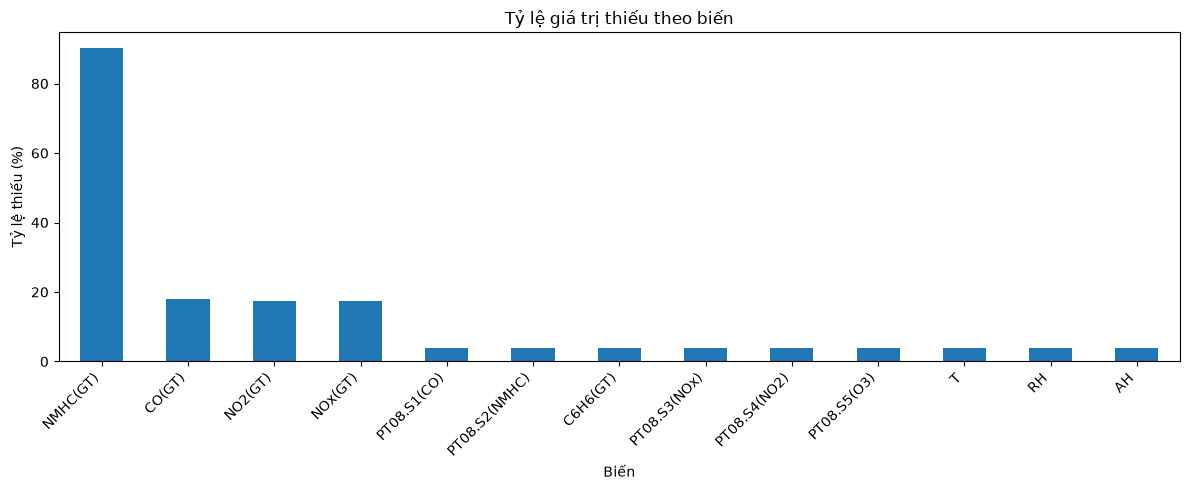

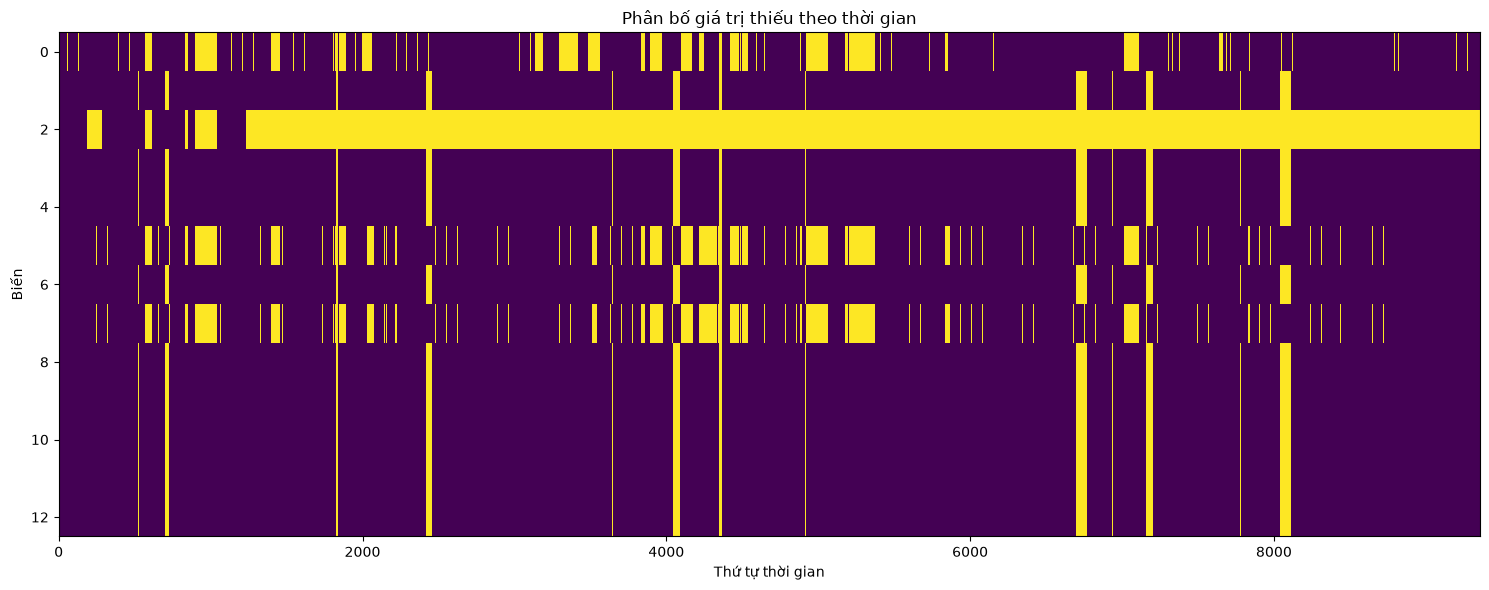

In [6]:
# Biểu đồ tỷ lệ giá trị thiếu
missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(12, 5))
missing_pct.plot(kind="bar")
plt.ylabel("Tỷ lệ thiếu (%)")
plt.xlabel("Biến")
plt.title("Tỷ lệ giá trị thiếu theo biến")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Hình thái thiếu dữ liệu theo thời gian
plt.figure(figsize=(15, 6))
plt.imshow(df.isna().T, aspect="auto", interpolation="none")
plt.xlabel("Thứ tự thời gian")
plt.ylabel("Biến")
plt.title("Phân bố giá trị thiếu theo thời gian")
plt.tight_layout()
plt.show()

In [7]:
print("Số giá trị âm theo từng cột:")
print((df < 0).sum())

Số giá trị âm theo từng cột:
CO(GT)            0
PT08.S1(CO)       0
NMHC(GT)          0
C6H6(GT)          0
PT08.S2(NMHC)     0
NOx(GT)           0
PT08.S3(NOx)      0
NO2(GT)           0
PT08.S4(NO2)      0
PT08.S5(O3)       0
T                13
RH                0
AH                0
dtype: int64


### 3.2. Chuẩn hóa timeline theo giờ

Trước khi tính rolling, lag và phân tích chuỗi thời gian, đưa dữ liệu về tần suất 1 giờ.

In [8]:
df = df.asfreq("h")

print("Kích thước sau asfreq:", df.shape)
print("\nKhoảng cách giữa các mốc thời gian:")
print(df.index.to_series().diff().value_counts().head())

print("\nKhoảng cách lớn nhất:")
print(df.index.to_series().diff().max())

Kích thước sau asfreq: (9357, 13)

Khoảng cách giữa các mốc thời gian:
0 days 01:00:00    9356
Name: count, dtype: int64

Khoảng cách lớn nhất:
0 days 01:00:00


### 3.3. Trực quan hóa chuỗi CO(GT)

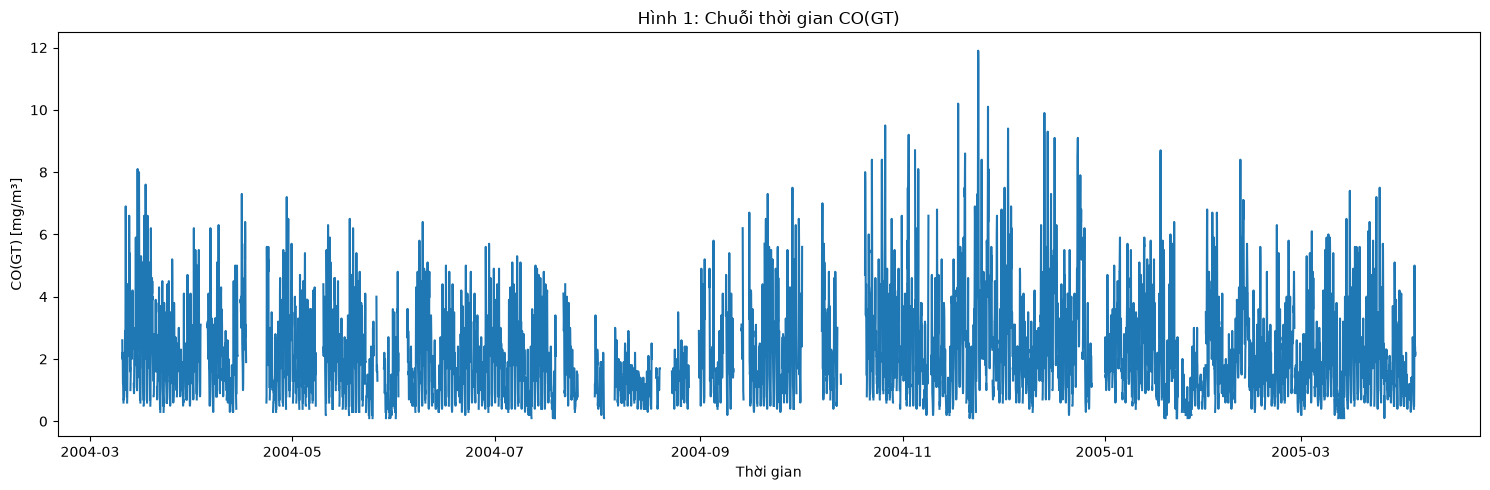

In [9]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["CO(GT)"])
plt.title("Hình 1: Chuỗi thời gian CO(GT)")
plt.xlabel("Thời gian")
plt.ylabel("CO(GT) [mg/m³]")
plt.tight_layout()
plt.show()

**Nhận xét:** Quan sát xu hướng biến động của CO theo thời gian, các giai đoạn có mức CO cao và các khoảng trống do dữ liệu thiếu. Cần dựa trên biểu đồ thực tế sau khi chạy notebook để hoàn thiện nhận xét.

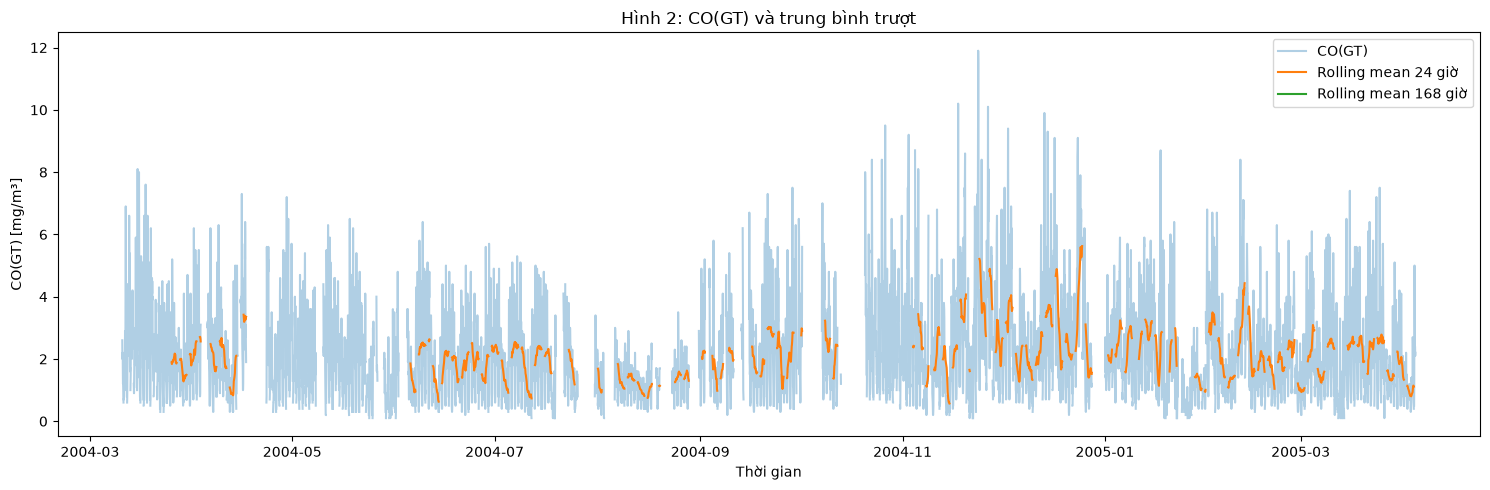

In [10]:
# Trung bình trượt 24 giờ và 7 ngày.
# min_periods giữ các khoảng thiếu thay vì tự điền giá trị.
co_rolling_24 = df["CO(GT)"].rolling(window=24, min_periods=24).mean()
co_rolling_168 = df["CO(GT)"].rolling(window=168, min_periods=168).mean()

plt.figure(figsize=(15, 5))
plt.plot(df.index, df["CO(GT)"], alpha=0.35, label="CO(GT)")
plt.plot(df.index, co_rolling_24, label="Rolling mean 24 giờ")
plt.plot(df.index, co_rolling_168, label="Rolling mean 168 giờ")
plt.title("Hình 2: CO(GT) và trung bình trượt")
plt.xlabel("Thời gian")
plt.ylabel("CO(GT) [mg/m³]")
plt.legend()
plt.tight_layout()
plt.show()

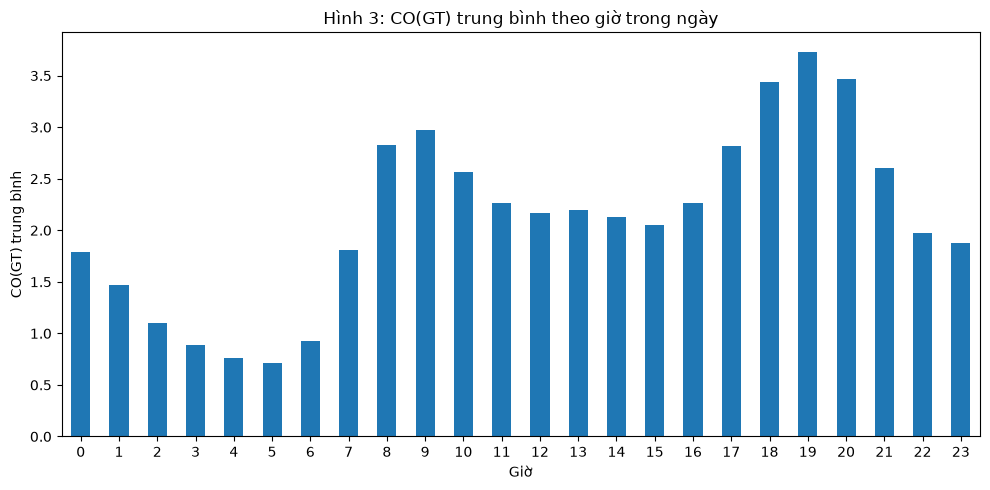

In [11]:
# Trung bình CO theo giờ trong ngày
co_by_hour = df.groupby(df.index.hour)["CO(GT)"].mean()

plt.figure(figsize=(10, 5))
co_by_hour.plot(kind="bar")
plt.title("Hình 3: CO(GT) trung bình theo giờ trong ngày")
plt.xlabel("Giờ")
plt.ylabel("CO(GT) trung bình")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

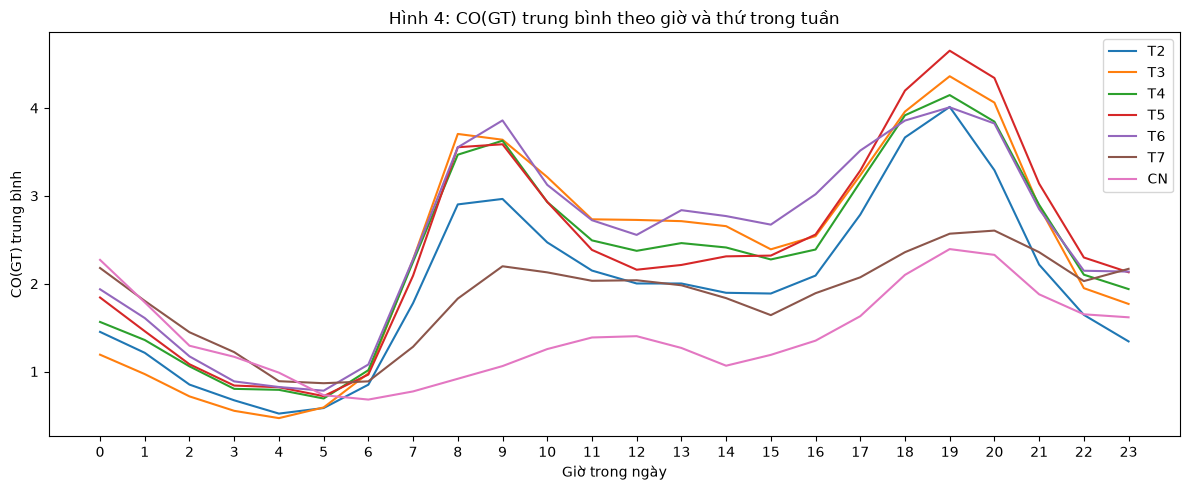

In [12]:
# Trung bình CO theo giờ trong ngày và thứ trong tuần
weekly_profile = (
    df.groupby([df.index.dayofweek, df.index.hour])["CO(GT)"]
      .mean()
      .unstack(level=0)
)

day_names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

plt.figure(figsize=(12, 5))
for day in weekly_profile.columns:
    plt.plot(weekly_profile.index, weekly_profile[day], label=day_names[day])

plt.title("Hình 4: CO(GT) trung bình theo giờ và thứ trong tuần")
plt.xlabel("Giờ trong ngày")
plt.ylabel("CO(GT) trung bình")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

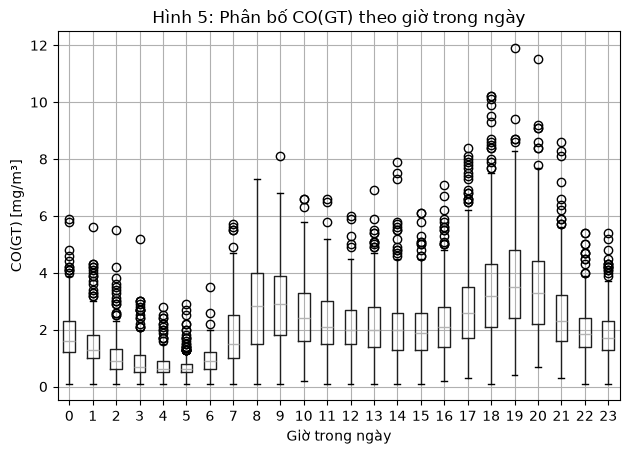

In [13]:
# Phân bố CO theo giờ trong ngày
co_hour_data = pd.DataFrame({
    "CO(GT)": df["CO(GT)"],
    "Hour": df.index.hour
})

plt.figure(figsize=(12, 5))
co_hour_data.boxplot(column="CO(GT)", by="Hour")
plt.title("Hình 5: Phân bố CO(GT) theo giờ trong ngày")
plt.suptitle("")
plt.xlabel("Giờ trong ngày")
plt.ylabel("CO(GT) [mg/m³]")
plt.tight_layout()
plt.show()

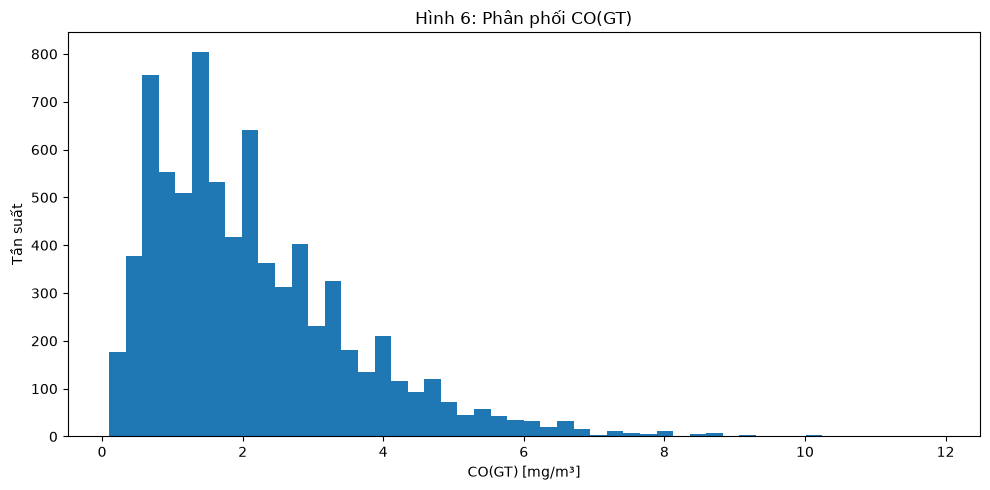

In [14]:
plt.figure(figsize=(10, 5))
plt.hist(df["CO(GT)"].dropna(), bins=50)
plt.title("Hình 6: Phân phối CO(GT)")
plt.xlabel("CO(GT) [mg/m³]")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.show()

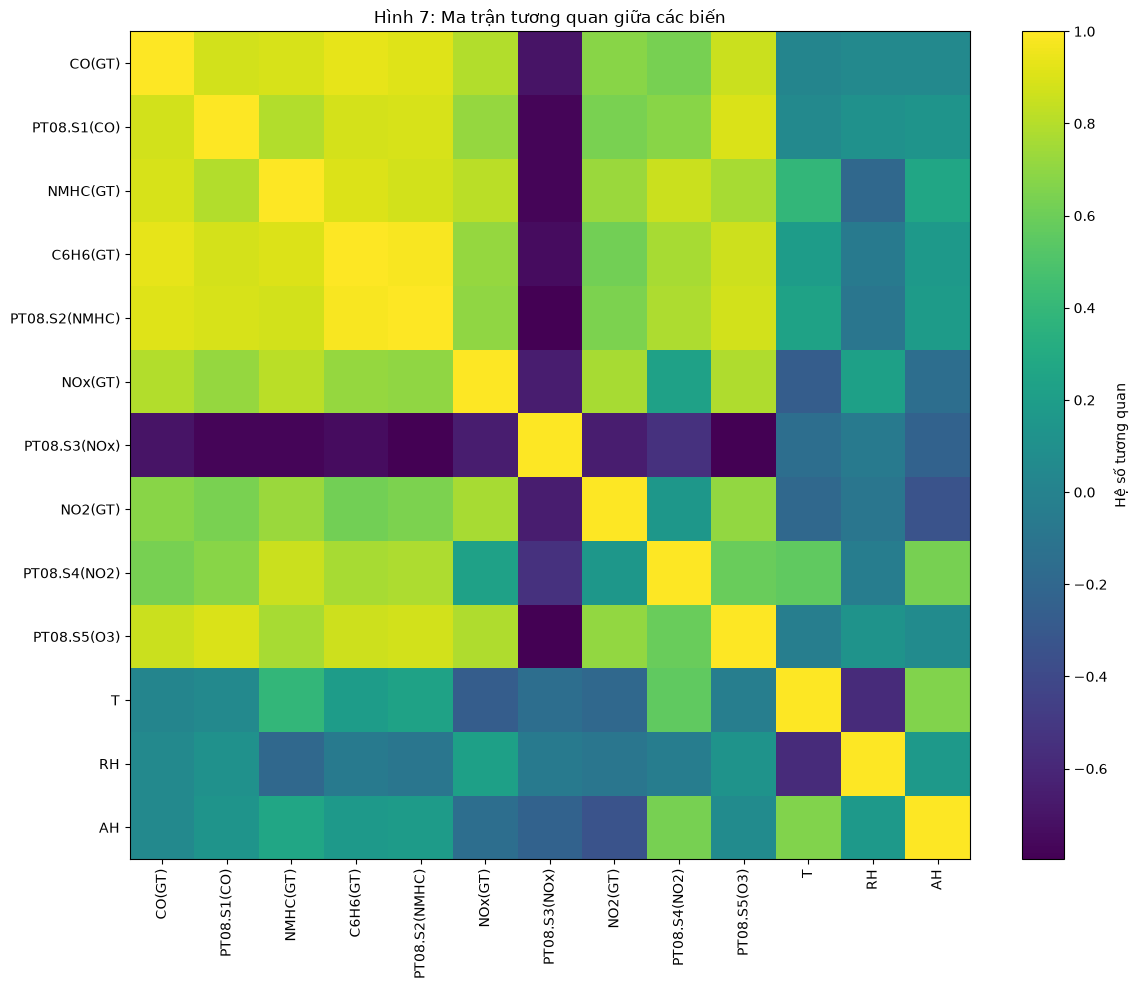

In [15]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Hệ số tương quan")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Hình 7: Ma trận tương quan giữa các biến")
plt.tight_layout()
plt.show()

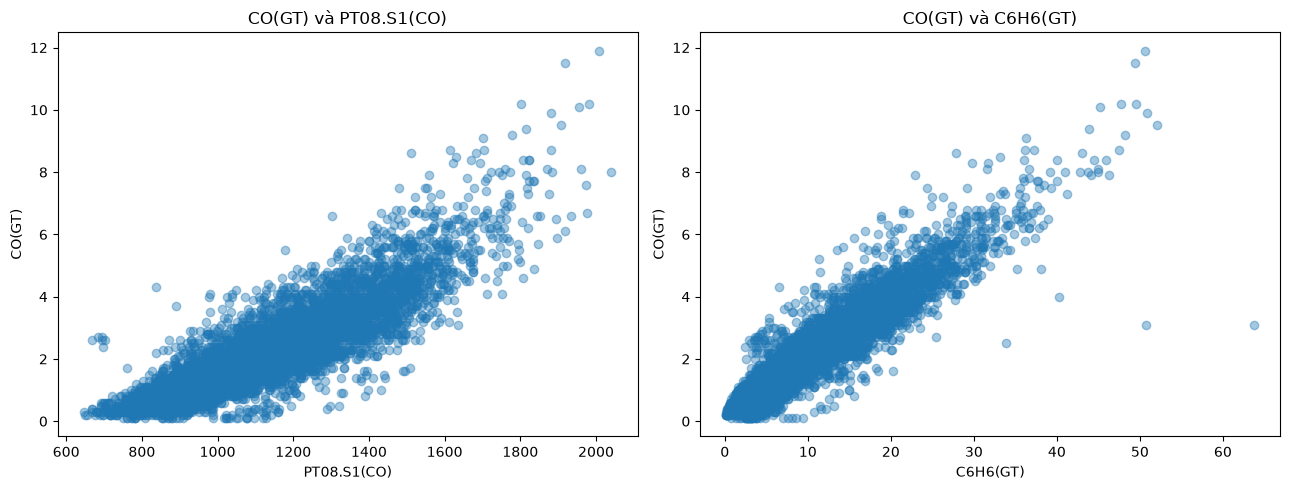

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["PT08.S1(CO)"], df["CO(GT)"], alpha=0.4)
axes[0].set_title("CO(GT) và PT08.S1(CO)")
axes[0].set_xlabel("PT08.S1(CO)")
axes[0].set_ylabel("CO(GT)")

axes[1].scatter(df["C6H6(GT)"], df["CO(GT)"], alpha=0.4)
axes[1].set_title("CO(GT) và C6H6(GT)")
axes[1].set_xlabel("C6H6(GT)")
axes[1].set_ylabel("CO(GT)")

plt.tight_layout()
plt.show()

## 4. Phân tích cấu trúc chuỗi thời gian

Các giá trị thiếu được nội suy tạm thời để phục vụ riêng cho biểu đồ phân rã, ACF và kiểm định ADF. Chuỗi đã nội suy không được dùng làm target huấn luyện.

In [17]:
co = df["CO(GT)"].copy()

# Nội suy chỉ phục vụ phân tích cấu trúc chuỗi
co_analysis = co.interpolate(method="time").ffill().bfill()

print("Số NaN còn lại:", co_analysis.isna().sum())
print("Số quan sát:", len(co_analysis))

Số NaN còn lại: 0
Số quan sát: 9357


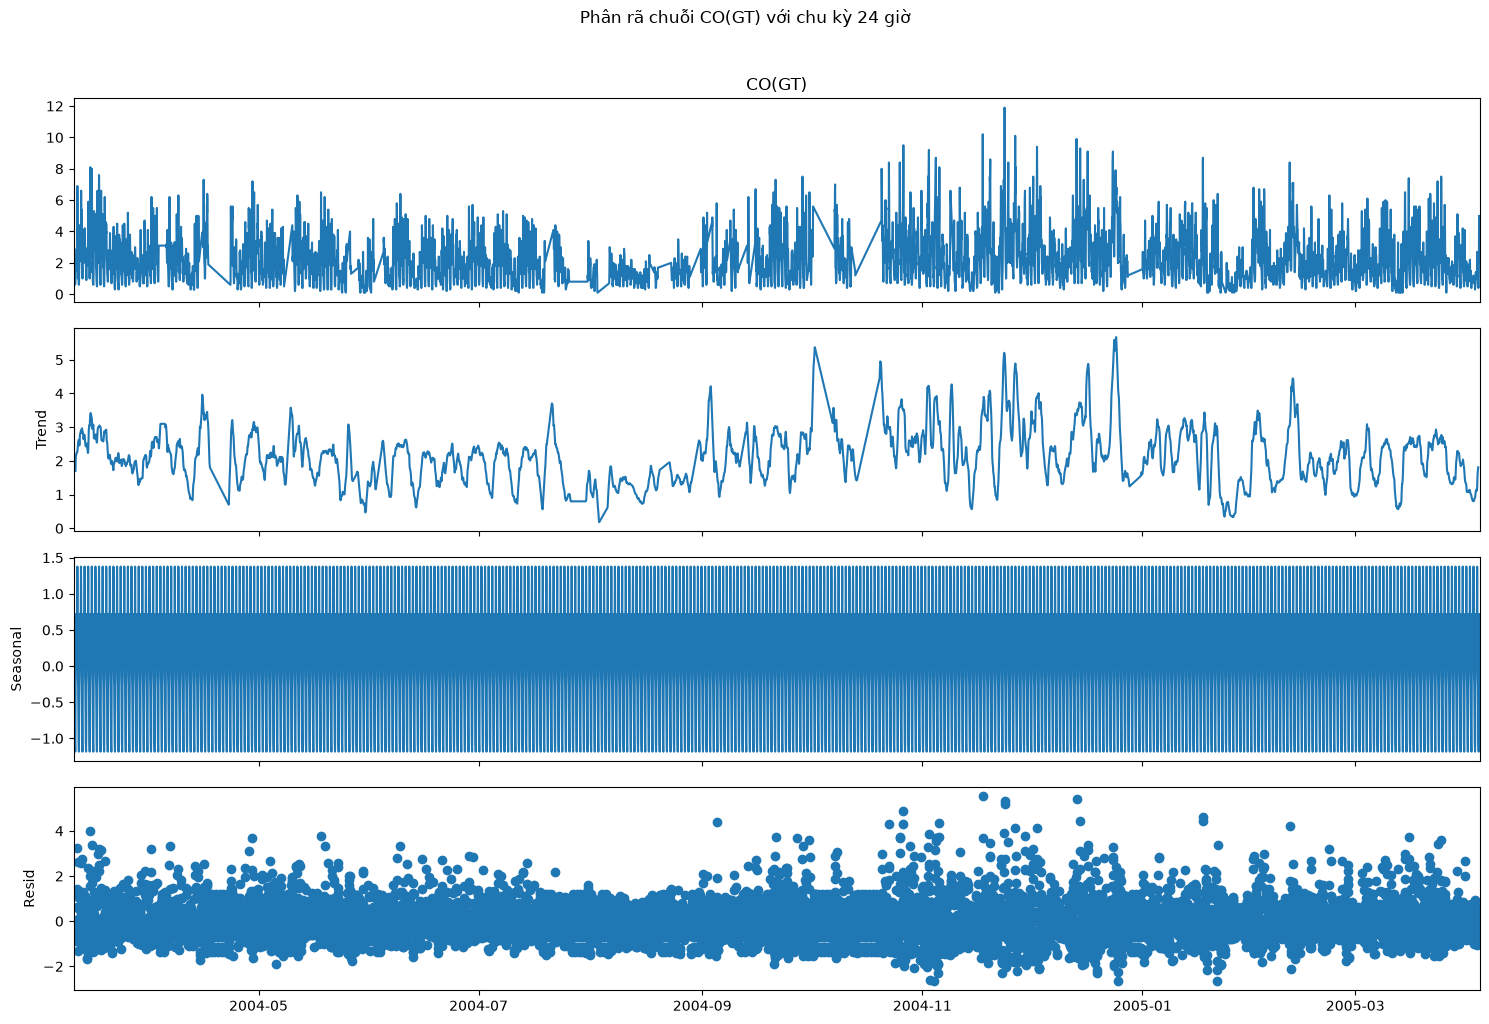

In [18]:
decomp_24 = seasonal_decompose(
    co_analysis,
    model="additive",
    period=24
)

fig = decomp_24.plot()
fig.set_size_inches(15, 10)
plt.suptitle("Phân rã chuỗi CO(GT) với chu kỳ 24 giờ", y=1.02)
plt.tight_layout()
plt.show()

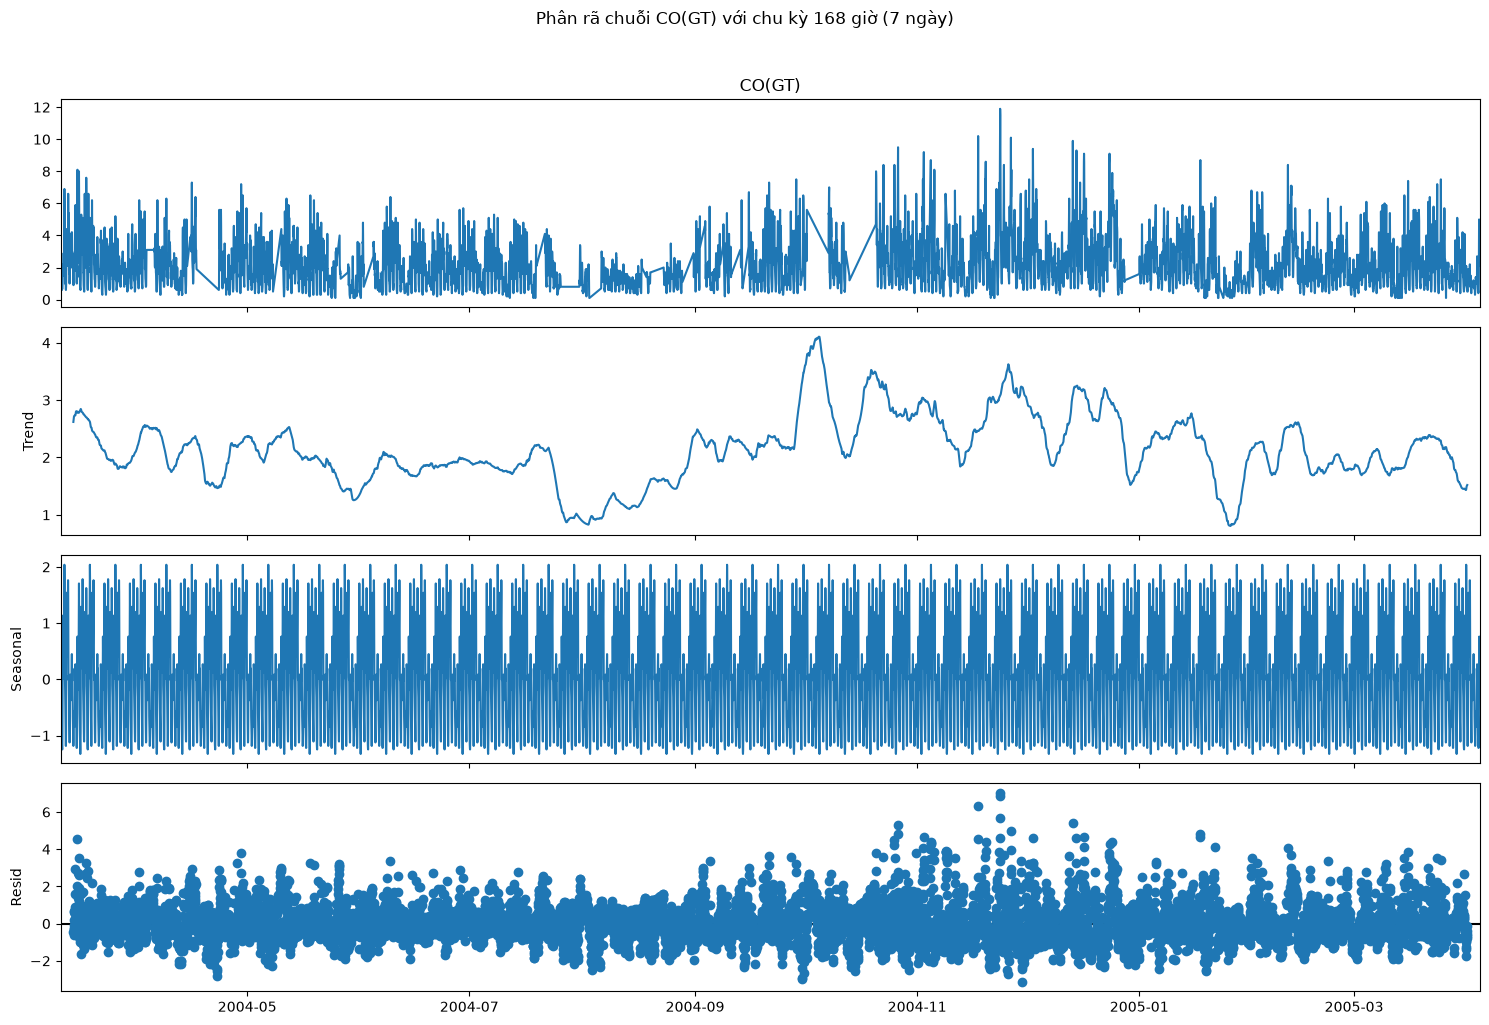

In [19]:
decomp_168 = seasonal_decompose(
    co_analysis,
    model="additive",
    period=168
)

fig = decomp_168.plot()
fig.set_size_inches(15, 10)
plt.suptitle("Phân rã chuỗi CO(GT) với chu kỳ 168 giờ (7 ngày)", y=1.02)
plt.tight_layout()
plt.show()

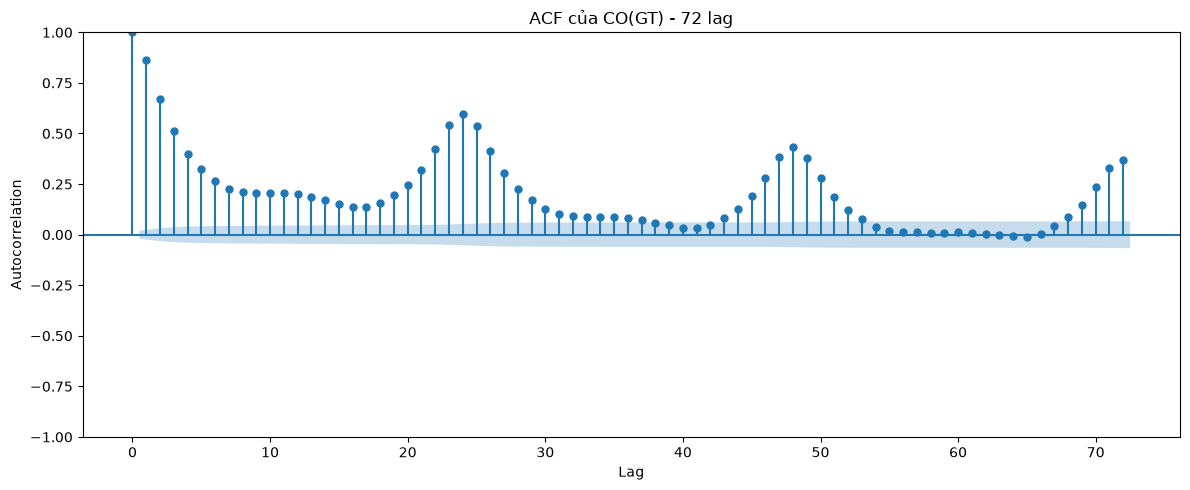

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(co_analysis, lags=72, ax=ax)
ax.set_title("ACF của CO(GT) - 72 lag")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

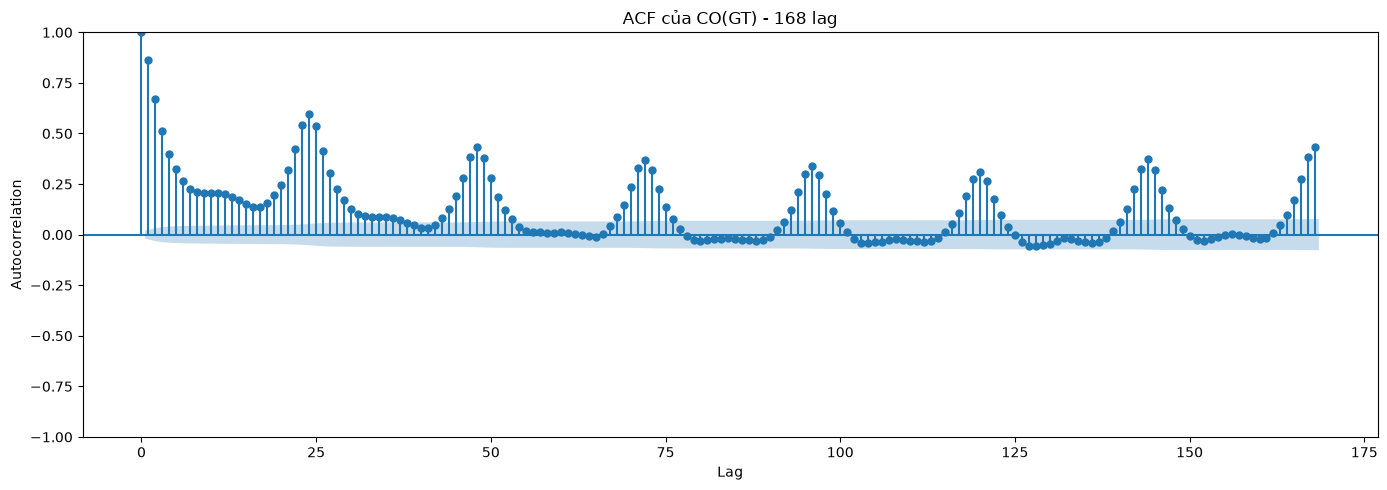

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(co_analysis, lags=168, ax=ax)
ax.set_title("ACF của CO(GT) - 168 lag")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

In [22]:
adf_result = adfuller(co_analysis)

print("=== KIỂM ĐỊNH ADF ===")
print(f"ADF statistic: {adf_result[0]:.6f}")
print(f"p-value: {adf_result[1]:.6f}")
print(f"Số lượng lag: {adf_result[2]}")
print(f"Số quan sát: {adf_result[3]}")

print("\nGiá trị tới hạn:")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.6f}")

if adf_result[1] < 0.05:
    print("\nBác bỏ H0 ở mức ý nghĩa 5%: chuỗi có dấu hiệu dừng theo kiểm định ADF.")
else:
    print("\nChưa đủ bằng chứng bác bỏ H0 ở mức ý nghĩa 5%.")

=== KIỂM ĐỊNH ADF ===
ADF statistic: -9.872735
p-value: 0.000000
Số lượng lag: 37
Số quan sát: 9319

Giá trị tới hạn:
1%: -3.431052
5%: -2.861850
10%: -2.566935

Bác bỏ H0 ở mức ý nghĩa 5%: chuỗi có dấu hiệu dừng theo kiểm định ADF.


## 5. Tiền xử lý dữ liệu

### 5.1. Loại cột có quá nhiều giá trị thiếu và xử lý missing

`NMHC(GT)` có tỷ lệ thiếu rất cao nên được loại khỏi tập đầu vào. Dữ liệu mô hình sử dụng forward fill tối đa 3 giờ, chỉ sử dụng thông tin quá khứ. Phương pháp interpolation chỉ được giữ ở phần so sánh EDA.

In [23]:
print("Tỷ lệ thiếu trước khi loại cột:")
display((df.isna().mean() * 100).sort_values(ascending=False))

df = df.drop(columns=["NMHC(GT)"])

print("Các cột sau khi loại NMHC(GT):")
print(df.columns.tolist())

# Forward fill tối đa 3 mốc giờ liên tiếp
df_ffill = df.ffill(limit=3)

print("\nSố NaN trước forward fill:")
display(df.isna().sum())

print("\nSố NaN sau forward fill:")
display(df_ffill.isna().sum())

Tỷ lệ thiếu trước khi loại cột:


NMHC(GT)         90.231912
CO(GT)           17.986534
NO2(GT)          17.548360
NOx(GT)          17.516298
PT08.S1(CO)       3.911510
PT08.S2(NMHC)     3.911510
C6H6(GT)          3.911510
PT08.S3(NOx)      3.911510
PT08.S4(NO2)      3.911510
PT08.S5(O3)       3.911510
T                 3.911510
RH                3.911510
AH                3.911510
dtype: float64

Các cột sau khi loại NMHC(GT):
['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Số NaN trước forward fill:


CO(GT)           1683
PT08.S1(CO)       366
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


Số NaN sau forward fill:


CO(GT)           1421
PT08.S1(CO)       324
C6H6(GT)          324
PT08.S2(NMHC)     324
NOx(GT)          1251
PT08.S3(NOx)      324
NO2(GT)          1253
PT08.S4(NO2)      324
PT08.S5(O3)       324
T                 324
RH                324
AH                324
dtype: int64

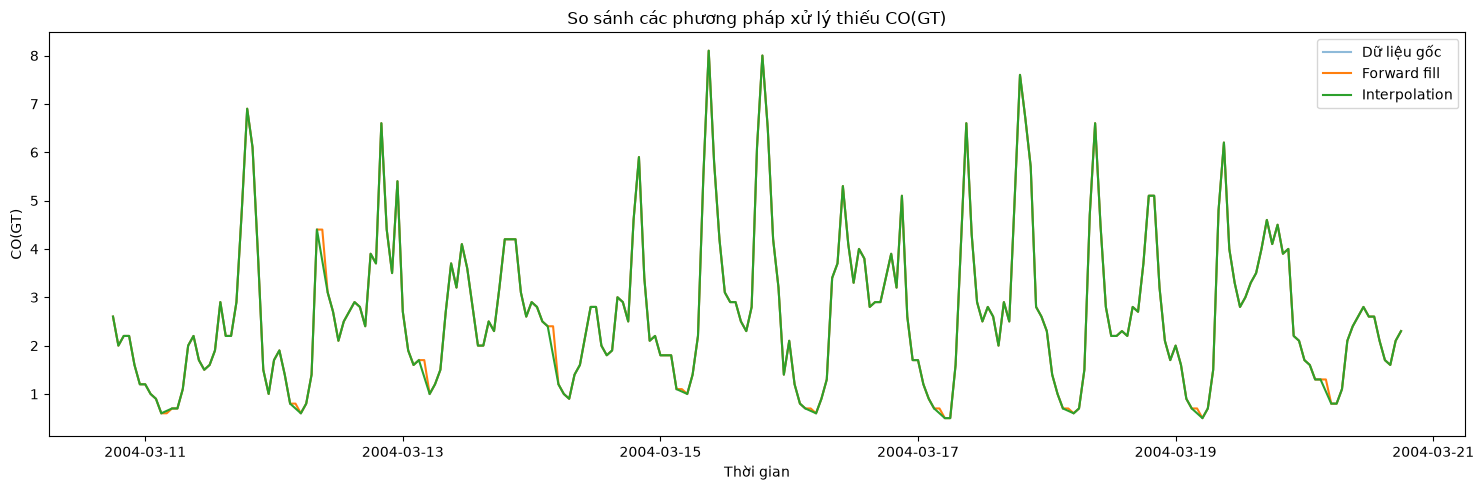

In [24]:
# So sánh forward fill và interpolation trên một khoảng thời gian ngắn.
# Interpolation chỉ để minh họa, không dùng cho tập huấn luyện.
start = df.index[0]
end = start + pd.Timedelta(days=10)

df_interp = df.interpolate(method="time", limit=3)

plt.figure(figsize=(15, 5))
plt.plot(df.loc[start:end, "CO(GT)"], label="Dữ liệu gốc", alpha=0.5)
plt.plot(df_ffill.loc[start:end, "CO(GT)"], label="Forward fill")
plt.plot(df_interp.loc[start:end, "CO(GT)"], label="Interpolation")
plt.title("So sánh các phương pháp xử lý thiếu CO(GT)")
plt.xlabel("Thời gian")
plt.ylabel("CO(GT)")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét về phương pháp điền thiếu:**
- Forward fill dùng giá trị quá khứ gần nhất và phù hợp hơn với quy trình dự báo online.
- Interpolation có thể dùng cả điểm phía sau khoảng thiếu, vì vậy không được áp dụng trên toàn bộ dữ liệu trước khi chia tập để huấn luyện.
- Target không được điền bằng forward fill, interpolation hoặc median. Các mẫu thiếu target sẽ bị loại riêng khi fit hoặc tính metric.

### 5.2. Tạo biến mục tiêu

Chọn `H = 1`: dùng thông tin tại thời điểm `t` để dự báo `CO(GT)` tại thời điểm `t+1 giờ`.

Target được tạo từ chuỗi CO gốc, không phải chuỗi đã forward fill.

In [25]:
H = 1
y = df["CO(GT)"].shift(-H)

print("Target:")
display(y.head())

print("Số giá trị target bị thiếu:", y.isna().sum())

Target:


2004-03-10 18:00:00    2.0
2004-03-10 19:00:00    2.2
2004-03-10 20:00:00    2.2
2004-03-10 21:00:00    1.6
2004-03-10 22:00:00    1.2
Freq: h, Name: CO(GT), dtype: float64

Số giá trị target bị thiếu: 1684


### 5.3. Feature Engineering

Các nhóm đặc trưng:
- Calendar: giờ, thứ, tháng, cuối tuần.
- Cyclical: sin/cos cho giờ và thứ trong tuần.
- Lag: CO trong quá khứ.
- Rolling: trung bình và độ lệch chuẩn trong cửa sổ quá khứ đến thời điểm hiện tại.
- Exogenous: các cảm biến và biến thời tiết tại thời điểm dự báo `t`.

Giả định các biến ngoại sinh tại thời điểm `t` đã có sẵn khi tạo dự báo cho `t+1`.

In [26]:
df_features = df_ffill.copy()

# Calendar features
df_features["hour"] = df_features.index.hour
df_features["dayofweek"] = df_features.index.dayofweek
df_features["month"] = df_features.index.month
df_features["is_weekend"] = (df_features["dayofweek"] >= 5).astype(int)

# Cyclical features
df_features["hour_sin"] = np.sin(2 * np.pi * df_features["hour"] / 24)
df_features["hour_cos"] = np.cos(2 * np.pi * df_features["hour"] / 24)
df_features["dow_sin"] = np.sin(2 * np.pi * df_features["dayofweek"] / 7)
df_features["dow_cos"] = np.cos(2 * np.pi * df_features["dayofweek"] / 7)

display(df_features[[
    "hour", "dayofweek", "month", "is_weekend",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos"
]].head())

,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos
2004-03-10 18:00:00,18,2,3,0,-1.000000,-1.836970e-16,0.974928,-0.222521
2004-03-10 19:00:00,19,2,3,0,-0.965926,2.588190e-01,0.974928,-0.222521
2004-03-10 20:00:00,20,2,3,0,-0.866025,5.000000e-01,0.974928,-0.222521
2004-03-10 21:00:00,21,2,3,0,-0.707107,7.071068e-01,0.974928,-0.222521
2004-03-10 22:00:00,22,2,3,0,-0.500000,8.660254e-01,0.974928,-0.222521


In [27]:
# Lag features: các giá trị CO trong quá khứ
for lag in [1, 2, 3, 24, 48, 168]:
    df_features[f"CO_lag_{lag}"] = df_features["CO(GT)"].shift(lag)

display(df_features[[
    "CO(GT)", "CO_lag_1", "CO_lag_2", "CO_lag_3",
    "CO_lag_24", "CO_lag_48", "CO_lag_168"
]].head(180))

,CO(GT),CO_lag_1,CO_lag_2,CO_lag_3,CO_lag_24,CO_lag_48,CO_lag_168
2004-03-10 18:00:00,2.6,NaN,NaN,NaN,NaN,NaN,NaN
2004-03-10 19:00:00,2.0,2.6,NaN,NaN,NaN,NaN,NaN
2004-03-10 20:00:00,2.2,2.0,2.6,NaN,NaN,NaN,NaN
2004-03-10 21:00:00,2.2,2.2,2.0,2.6,NaN,NaN,NaN
2004-03-10 22:00:00,1.6,2.2,2.2,2.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2004-03-18 01:00:00,1.4,2.3,2.6,2.8,1.2,1.2,1.0
2004-03-18 02:00:00,1.0,1.4,2.3,2.6,0.9,0.8,0.9
2004-03-18 03:00:00,0.7,1.0,1.4,2.3,0.7,0.7,0.6
2004-03-18 04:00:00,0.7,0.7,1.0,1.4,0.7,0.7,0.6


In [28]:
# Rolling features: cửa sổ bao gồm thời điểm hiện tại t.
# Vì dự báo CO(t+1), CO(t) được xem là thông tin đã quan sát.
df_features["CO_roll_mean_3"] = df_features["CO(GT)"].rolling(3, min_periods=3).mean()
df_features["CO_roll_std_3"] = df_features["CO(GT)"].rolling(3, min_periods=3).std()
df_features["CO_roll_mean_24"] = df_features["CO(GT)"].rolling(24, min_periods=24).mean()
df_features["CO_roll_std_24"] = df_features["CO(GT)"].rolling(24, min_periods=24).std()

display(df_features[[
    "CO(GT)", "CO_roll_mean_3", "CO_roll_std_3",
    "CO_roll_mean_24", "CO_roll_std_24"
]].head(30))

,CO(GT),CO_roll_mean_3,CO_roll_std_3,CO_roll_mean_24,CO_roll_std_24
2004-03-10 18:00:00,2.6,NaN,NaN,NaN,NaN
2004-03-10 19:00:00,2.0,NaN,NaN,NaN,NaN
2004-03-10 20:00:00,2.2,2.266667,0.305505,NaN,NaN
2004-03-10 21:00:00,2.2,2.133333,0.115470,NaN,NaN
2004-03-10 22:00:00,1.6,2.000000,0.346410,NaN,NaN
2004-03-10 23:00:00,1.2,1.666667,0.503322,NaN,NaN
2004-03-11 00:00:00,1.2,1.333333,0.230940,NaN,NaN
2004-03-11 01:00:00,1.0,1.133333,0.115470,NaN,NaN
2004-03-11 02:00:00,0.9,1.033333,0.152753,NaN,NaN
2004-03-11 03:00:00,0.6,0.833333,0.208167,NaN,NaN


In [29]:
# Các biến ngoại sinh được giả định sẵn có tại thời điểm t
exogenous_features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

feature_cols = [
    # Calendar
    "hour", "dayofweek", "month", "is_weekend",

    # Cyclical
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",

    # Lag
    "CO_lag_1", "CO_lag_2", "CO_lag_3",
    "CO_lag_24", "CO_lag_48", "CO_lag_168",

    # Rolling
    "CO_roll_mean_3", "CO_roll_std_3",
    "CO_roll_mean_24", "CO_roll_std_24",

    # Exogenous
    *exogenous_features
]

print("Số features:", len(feature_cols))
print(feature_cols)

Số features: 26
['hour', 'dayofweek', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'CO_lag_1', 'CO_lag_2', 'CO_lag_3', 'CO_lag_24', 'CO_lag_48', 'CO_lag_168', 'CO_roll_mean_3', 'CO_roll_std_3', 'CO_roll_mean_24', 'CO_roll_std_24', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [30]:
# Ghép features và target, không dropna tại bước này
data_model = df_features[feature_cols].copy()
data_model["y"] = y

X = data_model[feature_cols].copy()
y_model = data_model["y"].copy()

print("Số mẫu:", len(data_model))
print("Số target thiếu:", y_model.isna().sum())
print("Số giá trị thiếu trong features:", X.isna().sum().sum())

print("\nKhoảng cách thời gian:")
print(data_model.index.to_series().diff().value_counts().head())

print("\nKhoảng cách lớn nhất:")
print(data_model.index.to_series().diff().max())

Số mẫu: 9357
Số target thiếu: 1684
Số giá trị thiếu trong features: 18616

Khoảng cách thời gian:
0 days 01:00:00    9356
Name: count, dtype: int64

Khoảng cách lớn nhất:
0 days 01:00:00


### 5.4. Kiểm tra dữ liệu và nguy cơ leakage

Các kiểm tra dưới đây xác nhận timeline liên tục, target là giá trị giờ tiếp theo và các đặc trưng lag/rolling chỉ lấy dữ liệu tại hoặc trước thời điểm dự báo.

In [31]:
print("Index tăng dần:", X.index.is_monotonic_increasing)
print("Số index trùng:", X.index.duplicated().sum())
print("Tần suất thời gian:")
print(X.index.to_series().diff().value_counts().head())

print("\nTổng số NaN trong features:", X.isna().sum().sum())
print("Số NaN trong target:", y_model.isna().sum())

# Kiểm tra target tại một thời điểm bất kỳ
sample_time = X.index[100]
print("\nVí dụ kiểm tra target:")
print("Thời điểm đầu vào:", sample_time)
print("Target tương ứng:", sample_time + pd.Timedelta(hours=H))
print("Giá trị y:", y_model.loc[sample_time])
print("CO tại giờ tiếp theo:", df["CO(GT)"].shift(-H).loc[sample_time])

Index tăng dần: True
Số index trùng: 0
Tần suất thời gian:
0 days 01:00:00    9356
Name: count, dtype: int64

Tổng số NaN trong features: 18616
Số NaN trong target: 1684

Ví dụ kiểm tra target:
Thời điểm đầu vào: 2004-03-14 22:00:00
Target tương ứng: 2004-03-14 23:00:00
Giá trị y: 2.2
CO tại giờ tiếp theo: 2.2


## 6. Chia development và holdout theo thời gian

Giữ 336 mốc dự báo cuối cùng (14 ngày) làm holdout. Vì target được gắn tại thời điểm phát sinh dự báo `t` nhưng đại diện cho CO tại `t+1`, ta lấy 336 origin từ vị trí `-337` đến `-2`. Như vậy, target của holdout phủ 336 mốc giờ cuối cùng trong dữ liệu. Mốc cuối cùng của timeline chỉ đóng vai trò target, không làm origin dự báo vì không có giờ tiếp theo trong dữ liệu.

Không xóa các dòng thiếu target trước khi chia. Việc chia fold được thực hiện trên timeline đầy đủ.

In [32]:
HOLDOUT_HOURS = 24 * 14

# 336 origin cuối có target quan sát được trong timeline
X_dev = X.iloc[:-(HOLDOUT_HOURS + 1)].copy()
y_dev = y_model.loc[X_dev.index].copy()

X_holdout = X.iloc[-(HOLDOUT_HOURS + 1):-1].copy()
y_holdout = y_model.loc[X_holdout.index].copy()

print("Development:", X_dev.shape)
print("Holdout:", X_holdout.shape)

print("\nDevelopment origins:")
print(X_dev.index.min(), "->", X_dev.index.max())

print("\nHoldout origins:")
print(X_holdout.index.min(), "->", X_holdout.index.max())

print("\nHoldout target timestamps:")
print(X_holdout.index.min() + pd.Timedelta(hours=H),
      "->",
      X_holdout.index.max() + pd.Timedelta(hours=H))

print("\nTarget hợp lệ trong development:", y_dev.notna().sum())
print("Target hợp lệ trong holdout:", y_holdout.notna().sum())

Development: (9020, 26)
Holdout: (336, 26)

Development origins:
2004-03-10 18:00:00 -> 2005-03-21 13:00:00

Holdout origins:
2005-03-21 14:00:00 -> 2005-04-04 13:00:00

Holdout target timestamps:
2005-03-21 15:00:00 -> 2005-04-04 14:00:00

Target hợp lệ trong development: 7342
Target hợp lệ trong holdout: 331


### 6.1. TimeSeriesSplit

Mỗi fold kiểm tra 14 ngày (`test_size=336`) và có khoảng cách 24 giờ (`gap=24`) giữa train và test. Vì chia trên index đầy đủ, `gap=24` thực sự tương ứng 24 mốc giờ, kể cả khi một số target bị thiếu.

In [33]:
N_SPLITS = 5
TEST_SIZE = 24 * 14
GAP_HOURS = 24

ts_cv = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
    gap=GAP_HOURS
)

fold_splits = list(ts_cv.split(X_dev))

for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
    train_index = X_dev.index[train_idx]
    test_index = X_dev.index[test_idx]

    print(f"Fold {fold}")
    print(f"  Train: {train_index[0]} -> {train_index[-1]} ({len(train_idx)} mốc)")
    print(f"  Test : {test_index[0]} -> {test_index[-1]} ({len(test_idx)} mốc)")
    print(f"  Gap  : {(test_index[0] - train_index[-1]) / pd.Timedelta(hours=1) - 1:.0f} giờ")
    print()

Fold 1
  Train: 2004-03-10 18:00:00 -> 2005-01-09 13:00:00 (7316 mốc)
  Test : 2005-01-10 14:00:00 -> 2005-01-24 13:00:00 (336 mốc)
  Gap  : 24 giờ

Fold 2
  Train: 2004-03-10 18:00:00 -> 2005-01-23 13:00:00 (7652 mốc)
  Test : 2005-01-24 14:00:00 -> 2005-02-07 13:00:00 (336 mốc)
  Gap  : 24 giờ

Fold 3
  Train: 2004-03-10 18:00:00 -> 2005-02-06 13:00:00 (7988 mốc)
  Test : 2005-02-07 14:00:00 -> 2005-02-21 13:00:00 (336 mốc)
  Gap  : 24 giờ

Fold 4
  Train: 2004-03-10 18:00:00 -> 2005-02-20 13:00:00 (8324 mốc)
  Test : 2005-02-21 14:00:00 -> 2005-03-07 13:00:00 (336 mốc)
  Gap  : 24 giờ

Fold 5
  Train: 2004-03-10 18:00:00 -> 2005-03-06 13:00:00 (8660 mốc)
  Test : 2005-03-07 14:00:00 -> 2005-03-21 13:00:00 (336 mốc)
  Gap  : 24 giờ



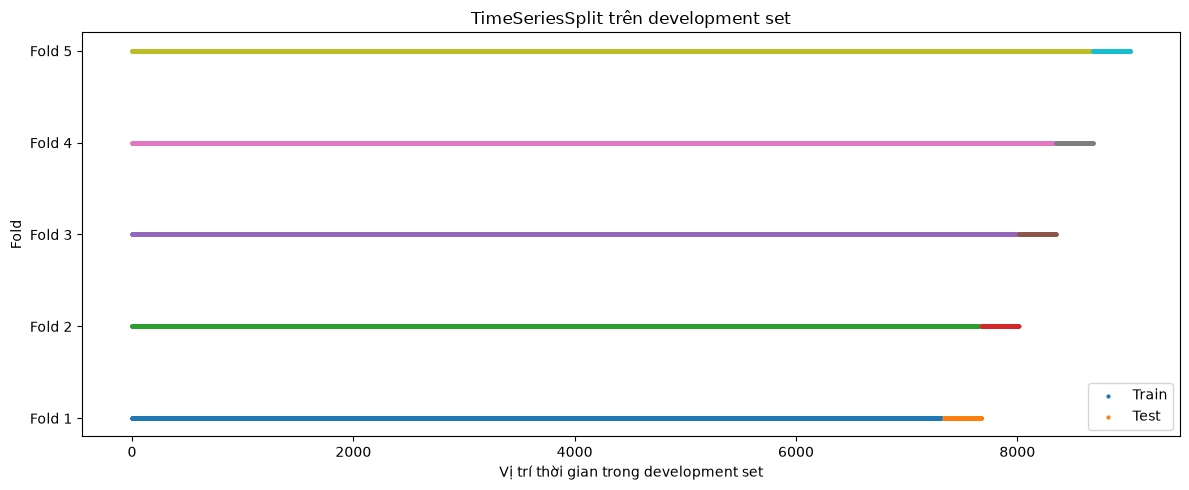

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
    ax.scatter(train_idx, [fold] * len(train_idx), s=4,
               label="Train" if fold == 1 else "")
    ax.scatter(test_idx, [fold] * len(test_idx), s=4,
               label="Test" if fold == 1 else "")

ax.set_yticks(range(1, N_SPLITS + 1))
ax.set_yticklabels([f"Fold {i}" for i in range(1, N_SPLITS + 1)])
ax.set_xlabel("Vị trí thời gian trong development set")
ax.set_ylabel("Fold")
ax.set_title("TimeSeriesSplit trên development set")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Hàm đánh giá và baseline

Metric gồm MAE, RMSE, sMAPE, R² và MASE. Các metric chỉ được tính trên những thời điểm có cả target và prediction hợp lệ.

MASE sử dụng sai số naive một bước trên chuỗi train đầy đủ theo timeline; không nén các mốc thiếu target trước khi tính sai phân.

In [35]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominator = np.abs(y_true) + np.abs(y_pred)
    values = np.zeros_like(denominator, dtype=float)

    nonzero = denominator != 0
    values[nonzero] = (
        2 * np.abs(y_true[nonzero] - y_pred[nonzero])
        / denominator[nonzero]
    )

    return np.mean(values) * 100


def evaluate_metrics(y_true, y_pred, y_train):
    # Đồng bộ theo index và chỉ giữ các target/prediction hợp lệ
    aligned = pd.concat(
        [
            y_true.rename("y_true"),
            y_pred.rename("y_pred")
        ],
        axis=1
    )

    valid = aligned["y_true"].notna() & aligned["y_pred"].notna()
    aligned = aligned.loc[valid]

    if len(aligned) == 0:
        return {
            "N": 0, "MAE": np.nan, "RMSE": np.nan,
            "sMAPE": np.nan, "R2": np.nan, "MASE": np.nan
        }

    yt = aligned["y_true"]
    yp = aligned["y_pred"]

    # MASE: sai số naive 1 bước tính trên các cặp giờ liền kề hợp lệ
    naive_scale = y_train.diff().abs().mean()

    mase_value = (
        mean_absolute_error(yt, yp) / naive_scale
        if pd.notna(naive_scale) and naive_scale != 0
        else np.nan
    )

    return {
        "N": len(aligned),
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "sMAPE": smape(yt, yp),
        "R2": r2_score(yt, yp) if len(yt) >= 2 else np.nan,
        "MASE": mase_value
    }

In [36]:
def predict_baselines(train_index, y_train, test_index):
    # Persistence: dự báo CO(t+1) bằng CO(t)
    pred_persistence = df["CO(GT)"].reindex(test_index)

    # Seasonal Naive 24h:
    # CO(t+1) được dự báo bằng CO(t-23), cùng giờ ngày trước
    seasonal_index = test_index - pd.Timedelta(hours=23)
    pred_seasonal = df["CO(GT)"].reindex(seasonal_index)
    pred_seasonal.index = test_index

    # Hourly Mean: trung bình target theo giờ của thời điểm target (t+1)
    valid_train = y_train.notna()
    y_train_valid = y_train.loc[valid_train]
    train_target_hours = (
        y_train_valid.index + pd.Timedelta(hours=1)
    ).hour

    hourly_mean = (
        pd.DataFrame({
            "target_hour": train_target_hours,
            "y": y_train_valid.values
        })
        .groupby("target_hour")["y"]
        .mean()
    )

    test_target_hours = (
        test_index + pd.Timedelta(hours=1)
    ).hour

    pred_hourly = pd.Series(
        test_target_hours,
        index=test_index
    ).map(hourly_mean)

    return {
        "Persistence": pred_persistence,
        "Seasonal Naive 24h": pred_seasonal,
        "Hourly Mean": pred_hourly
    }

In [37]:
baseline_cv_rows = []
baseline_oof = {
    "Persistence": [],
    "Seasonal Naive 24h": [],
    "Hourly Mean": []
}

for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
    train_index = X_dev.index[train_idx]
    test_index = X_dev.index[test_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_test_fold = y_dev.iloc[test_idx]

    predictions = predict_baselines(
        train_index,
        y_train_fold,
        test_index
    )

    for model_name, prediction in predictions.items():
        metrics = evaluate_metrics(
            y_test_fold,
            prediction,
            y_train_fold
        )

        baseline_cv_rows.append({
            "Fold": fold,
            "Model": model_name,
            **metrics
        })

        fold_prediction = pd.DataFrame({
            "y_true": y_test_fold,
            "y_pred": prediction
        }, index=test_index)

        fold_prediction["fold"] = fold
        baseline_oof[model_name].append(fold_prediction)

baseline_cv = pd.DataFrame(baseline_cv_rows)
display(baseline_cv)

,Fold,Model,N,MAE,RMSE,sMAPE,R2,MASE
0,1,Persistence,288,0.648264,0.966541,30.211324,0.607271,1.163604
1,1,Seasonal Naive 24h,275,1.349818,1.830330,55.991737,-0.396542,2.422862
2,1,Hourly Mean,297,1.002625,1.307143,45.071371,0.294979,1.799666
3,2,Persistence,304,0.435855,0.719626,26.171748,0.708323,0.775153
4,2,Seasonal Naive 24h,290,0.821379,1.180765,49.747651,0.218452,1.460793
5,2,Hourly Mean,311,1.089259,1.351048,58.702369,-0.026352,1.937207
6,3,Persistence,326,0.460123,0.679272,22.414976,0.743272,0.826366
7,3,Seasonal Naive 24h,327,0.888991,1.274485,40.050530,0.106067,1.596600
8,3,Hourly Mean,331,0.911871,1.205087,43.046059,0.195882,1.637692
9,4,Persistence,328,0.482927,0.729726,24.920135,0.605094,0.875195


## 8. Ridge: chọn alpha bằng inner time-series CV

Không dùng trực tiếp `RidgeCV` sau khi lọc target thiếu, vì khi đó `gap=24` bên trong RidgeCV sẽ tính trên số dòng còn lại chứ không còn là 24 giờ. Thay vào đó, inner folds được tạo trên timeline đầy đủ; chỉ sau khi chia fold mới lọc target hợp lệ để fit và chấm điểm.

Imputer và StandardScaler đều nằm trong Pipeline nên chỉ được fit trên phần train của từng inner fold.

In [38]:
alphas = np.logspace(-3, 3, 20)

def make_ridge_pipeline(alpha):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])


def select_ridge_alpha(
    X_train_full,
    y_train_full,
    alpha_values=alphas,
    n_splits=4,
    inner_test_size=24 * 7,
    gap=24
):
    inner_cv = TimeSeriesSplit(
        n_splits=n_splits,
        test_size=inner_test_size,
        gap=gap
    )

    alpha_scores = []

    for alpha in alpha_values:
        fold_scores = []

        for inner_train_idx, inner_val_idx in inner_cv.split(X_train_full):
            X_inner_train = X_train_full.iloc[inner_train_idx]
            y_inner_train = y_train_full.iloc[inner_train_idx]

            X_inner_val = X_train_full.iloc[inner_val_idx]
            y_inner_val = y_train_full.iloc[inner_val_idx]

            valid_train = y_inner_train.notna()
            valid_val = y_inner_val.notna()

            if valid_train.sum() == 0 or valid_val.sum() == 0:
                continue

            model = make_ridge_pipeline(alpha)
            model.fit(
                X_inner_train.loc[valid_train],
                y_inner_train.loc[valid_train]
            )

            prediction = pd.Series(
                model.predict(X_inner_val.loc[valid_val]),
                index=X_inner_val.index[valid_val]
            )

            fold_scores.append(
                mean_absolute_error(
                    y_inner_val.loc[valid_val],
                    prediction
                )
            )

        mean_score = np.mean(fold_scores) if fold_scores else np.inf
        alpha_scores.append({
            "alpha": alpha,
            "inner_MAE": mean_score
        })

    score_table = pd.DataFrame(alpha_scores)
    best_alpha = score_table.loc[
        score_table["inner_MAE"].idxmin(), "alpha"
    ]

    return float(best_alpha), score_table

In [39]:
ridge_cv_rows = []
ridge_oof_parts = []
ridge_alpha_by_fold = []

for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
    X_train_full = X_dev.iloc[train_idx]
    y_train_full = y_dev.iloc[train_idx]

    X_test = X_dev.iloc[test_idx]
    y_test = y_dev.iloc[test_idx]

    valid_train = y_train_full.notna()
    valid_test = y_test.notna()

    best_alpha, alpha_table = select_ridge_alpha(
        X_train_full,
        y_train_full
    )

    ridge_model = make_ridge_pipeline(best_alpha)
    ridge_model.fit(
        X_train_full.loc[valid_train],
        y_train_full.loc[valid_train]
    )

    # Dự báo trên toàn bộ test window; metric chỉ dùng target hợp lệ
    prediction = pd.Series(
        ridge_model.predict(X_test),
        index=X_test.index
    )

    metrics = evaluate_metrics(
        y_test,
        prediction,
        y_train_full
    )

    ridge_cv_rows.append({
        "Fold": fold,
        "Model": "Ridge",
        "alpha": best_alpha,
        **metrics
    })

    ridge_alpha_by_fold.append(best_alpha)

    fold_prediction = pd.DataFrame({
        "y_true": y_test,
        "y_pred": prediction
    }, index=X_test.index)

    fold_prediction["residual"] = (
        fold_prediction["y_true"] - fold_prediction["y_pred"]
    )
    fold_prediction["fold"] = fold
    fold_prediction["alpha"] = best_alpha
    ridge_oof_parts.append(fold_prediction)

ridge_cv = pd.DataFrame(ridge_cv_rows)
ridge_oof = pd.concat(ridge_oof_parts).sort_index()

display(ridge_cv)
print("Alpha được chọn theo từng fold:", ridge_alpha_by_fold)

,Fold,Model,alpha,N,MAE,RMSE,sMAPE,R2,MASE
0,1,Ridge,0.001,297,0.658894,0.908407,32.192044,0.659500,1.182684
1,2,Ridge,1000.000,311,0.616920,0.805908,50.995868,0.634804,1.097170
2,3,Ridge,0.001,331,0.476719,0.738598,22.701751,0.697936,0.856173
3,4,Ridge,0.001,332,0.428726,0.616160,23.744393,0.718365,0.776968
4,5,Ridge,0.001,321,0.585441,0.831964,31.832870,0.682780,1.067439


Alpha được chọn theo từng fold: [0.001, 1000.0, 0.001, 0.001, 0.001]


## 9. Random Forest

Random Forest được đánh giá trên cùng các outer folds như Ridge và baseline. Target thiếu được lọc khỏi train; missing trong features được xử lý bằng Imputer trong Pipeline.

In [40]:
def make_rf_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

In [41]:
rf_cv_rows = []
rf_oof_parts = []

for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
    X_train_full = X_dev.iloc[train_idx]
    y_train_full = y_dev.iloc[train_idx]

    X_test = X_dev.iloc[test_idx]
    y_test = y_dev.iloc[test_idx]

    valid_train = y_train_full.notna()

    rf_model = make_rf_pipeline()
    rf_model.fit(
        X_train_full.loc[valid_train],
        y_train_full.loc[valid_train]
    )

    prediction = pd.Series(
        rf_model.predict(X_test),
        index=X_test.index
    )

    metrics = evaluate_metrics(
        y_test,
        prediction,
        y_train_full
    )

    rf_cv_rows.append({
        "Fold": fold,
        "Model": "Random Forest",
        **metrics
    })

    fold_prediction = pd.DataFrame({
        "y_true": y_test,
        "y_pred": prediction
    }, index=X_test.index)

    fold_prediction["residual"] = (
        fold_prediction["y_true"] - fold_prediction["y_pred"]
    )
    fold_prediction["fold"] = fold
    rf_oof_parts.append(fold_prediction)

rf_cv = pd.DataFrame(rf_cv_rows)
rf_oof = pd.concat(rf_oof_parts).sort_index()

display(rf_cv)

,Fold,Model,N,MAE,RMSE,sMAPE,R2,MASE
0,1,Random Forest,297,0.722101,1.062625,32.541115,0.534075,1.296138
1,2,Random Forest,311,0.461268,0.637685,32.136610,0.771352,0.820349
2,3,Random Forest,331,0.430293,0.659878,20.583416,0.758893,0.772793
3,4,Random Forest,332,0.364858,0.550677,19.807397,0.775046,0.661223
4,5,Random Forest,321,0.491695,0.666812,28.642454,0.796221,0.896512


## 10. Tổng hợp kết quả cross-validation

Bảng được tạo trực tiếp từ kết quả thực nghiệm của từng fold; không nhập metric bằng tay.

In [42]:
cv_all = pd.concat([
    baseline_cv,
    ridge_cv[["Fold", "Model", "N", "MAE", "RMSE", "sMAPE", "R2", "MASE"]],
    rf_cv
], ignore_index=True)

metric_columns = ["N", "MAE", "RMSE", "sMAPE", "R2", "MASE"]

cv_summary = (
    cv_all.groupby("Model")[metric_columns]
    .agg(["mean", "std"])
)

display(cv_all)
display(cv_summary)

,Fold,Model,N,MAE,RMSE,sMAPE,R2,MASE
0,1,Persistence,288,0.648264,0.966541,30.211324,0.607271,1.163604
1,1,Seasonal Naive 24h,275,1.349818,1.830330,55.991737,-0.396542,2.422862
2,1,Hourly Mean,297,1.002625,1.307143,45.071371,0.294979,1.799666
3,2,Persistence,304,0.435855,0.719626,26.171748,0.708323,0.775153
4,2,Seasonal Naive 24h,290,0.821379,1.180765,49.747651,0.218452,1.460793
5,2,Hourly Mean,311,1.089259,1.351048,58.702369,-0.026352,1.937207
6,3,Persistence,326,0.460123,0.679272,22.414976,0.743272,0.826366
7,3,Seasonal Naive 24h,327,0.888991,1.274485,40.050530,0.106067,1.596600
8,3,Hourly Mean,331,0.911871,1.205087,43.046059,0.195882,1.637692
9,4,Persistence,328,0.482927,0.729726,24.920135,0.605094,0.875195


N                  MAE                RMSE            \
                     mean        std      mean       std      mean       std   
Model                                                                          
Hourly Mean         318.4  14.690133  0.916301  0.132181  1.194093  0.144882   
Persistence         312.0  16.552945  0.534733  0.104173  0.812051  0.141632   
Random Forest       318.4  14.690133  0.494043  0.135870  0.715535  0.199488   
Ridge               318.4  14.690133  0.553340  0.096972  0.780207  0.110020   
Seasonal Naive 24h  306.2  23.101948  0.922602  0.244245  1.315253  0.293209   

                        sMAPE                   R2                MASE  \
                         mean        std      mean       std      mean   
Model                                                                    
Hourly Mean         45.771588   7.522781  0.232669  0.168432  1.648510   
Persistence         27.103818   3.851680  0.647017  0.074365  0.963816   
Random Forest       26.742198   6.171713  0.727118  0.108748  0.889403   
Ridge               32.293385  11.347796  0.678677  0.032617  0.996087   
Seasonal Naive 24h  45.494779   7.092829  0.067512  0.305946  1.660523   

                              
                         std  
Model                         
Hourly Mean         0.222688  
Persistence         0.192651  
Random Forest       0.242856  
Ridge               0.171549  
Seasonal Naive 24h  0.434486

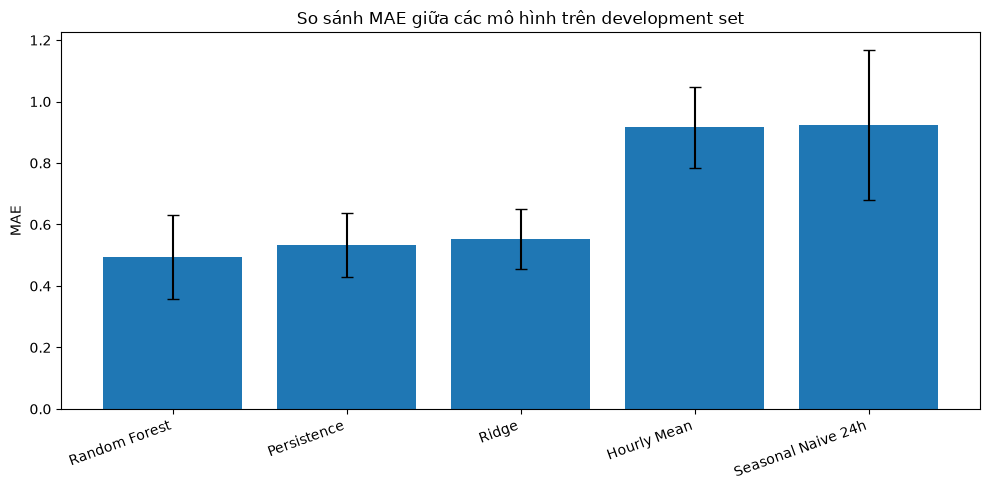

In [43]:
# Biểu đồ so sánh MAE trung bình qua các fold
mae_summary = (
    cv_all.groupby("Model")["MAE"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

plt.figure(figsize=(10, 5))
plt.bar(mae_summary.index, mae_summary["mean"], yerr=mae_summary["std"], capsize=4)
plt.title("So sánh MAE giữa các mô hình trên development set")
plt.ylabel("MAE")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 11. Huấn luyện cuối cùng và đánh giá holdout

Sau khi cross-validation hoàn tất, huấn luyện lại mô hình trên toàn bộ development set. Ridge chọn alpha bằng inner CV trên development set. Holdout không được sử dụng để chọn alpha hoặc cấu hình mô hình.

In [44]:
# Baseline trên holdout
holdout_baseline_predictions = predict_baselines(
    X_dev.index,
    y_dev,
    X_holdout.index
)

# Ridge: chọn alpha trên development set đầy đủ
final_ridge_alpha, final_alpha_table = select_ridge_alpha(
    X_dev,
    y_dev
)

final_ridge = make_ridge_pipeline(final_ridge_alpha)
valid_dev = y_dev.notna()

final_ridge.fit(
    X_dev.loc[valid_dev],
    y_dev.loc[valid_dev]
)

ridge_holdout_prediction = pd.Series(
    final_ridge.predict(X_holdout),
    index=X_holdout.index
)

print("Alpha cuối cùng của Ridge:", final_ridge_alpha)
display(final_alpha_table.sort_values("inner_MAE").head())

Alpha cuối cùng của Ridge: 0.001


,alpha,inner_MAE
0,0.001000,0.509416
1,0.002069,0.509417
2,0.004281,0.509417
3,0.008859,0.509417
4,0.018330,0.509418


In [45]:
# Random Forest: fit trên toàn bộ development set có target hợp lệ
final_rf = make_rf_pipeline()

final_rf.fit(
    X_dev.loc[valid_dev],
    y_dev.loc[valid_dev]
)

rf_holdout_prediction = pd.Series(
    final_rf.predict(X_holdout),
    index=X_holdout.index
)

In [46]:
# Tính metric holdout cho tất cả mô hình
holdout_predictions = {
    **holdout_baseline_predictions,
    "Ridge": ridge_holdout_prediction,
    "Random Forest": rf_holdout_prediction
}

holdout_rows = []

for model_name, prediction in holdout_predictions.items():
    metrics = evaluate_metrics(
        y_holdout,
        prediction,
        y_dev
    )

    holdout_rows.append({
        "Model": model_name,
        **metrics
    })

holdout_results = (
    pd.DataFrame(holdout_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(holdout_results)

,Model,N,MAE,RMSE,sMAPE,R2,MASE
0,Random Forest,331,0.333872,0.483620,18.751401,0.862207,0.604743
1,Ridge,331,0.390815,0.601761,24.195675,0.786663,0.707885
2,Persistence,326,0.491104,0.779944,25.233488,0.641265,0.889539
3,Seasonal Naive 24h,327,0.688991,0.997535,35.368639,0.413292,1.247972
4,Hourly Mean,331,0.815111,1.049676,42.080361,0.350875,1.476413


**Lưu ý khi diễn giải:** Số mẫu `N` trong bảng holdout là số target thực sự quan sát được và có prediction hợp lệ. Nó có thể nhỏ hơn 336 do target gốc có các khoảng thiếu.

## 12. Phân tích lỗi của Ridge trên holdout

Ridge được chọn làm mô hình phân tích lỗi. Các biểu đồ dưới đây sử dụng dự báo trên holdout, không sử dụng dự báo train.

In [47]:
ridge_holdout = pd.DataFrame({
    "y_true": y_holdout,
    "y_pred": ridge_holdout_prediction
}, index=X_holdout.index)

ridge_holdout["residual"] = (
    ridge_holdout["y_true"] - ridge_holdout["y_pred"]
)

# Đổi index từ thời điểm tạo dự báo t sang thời điểm target t+1
ridge_holdout_plot = ridge_holdout.copy()
ridge_holdout_plot.index = (
    ridge_holdout_plot.index + pd.Timedelta(hours=H)
)

display(ridge_holdout.head())

,y_true,y_pred,residual
2005-03-21 14:00:00,2.1,2.379675,-0.279675
2005-03-21 15:00:00,2.0,2.232267,-0.232267
2005-03-21 16:00:00,2.6,2.280244,0.319756
2005-03-21 17:00:00,4.5,2.849684,1.650316
2005-03-21 18:00:00,6.4,4.554388,1.845612


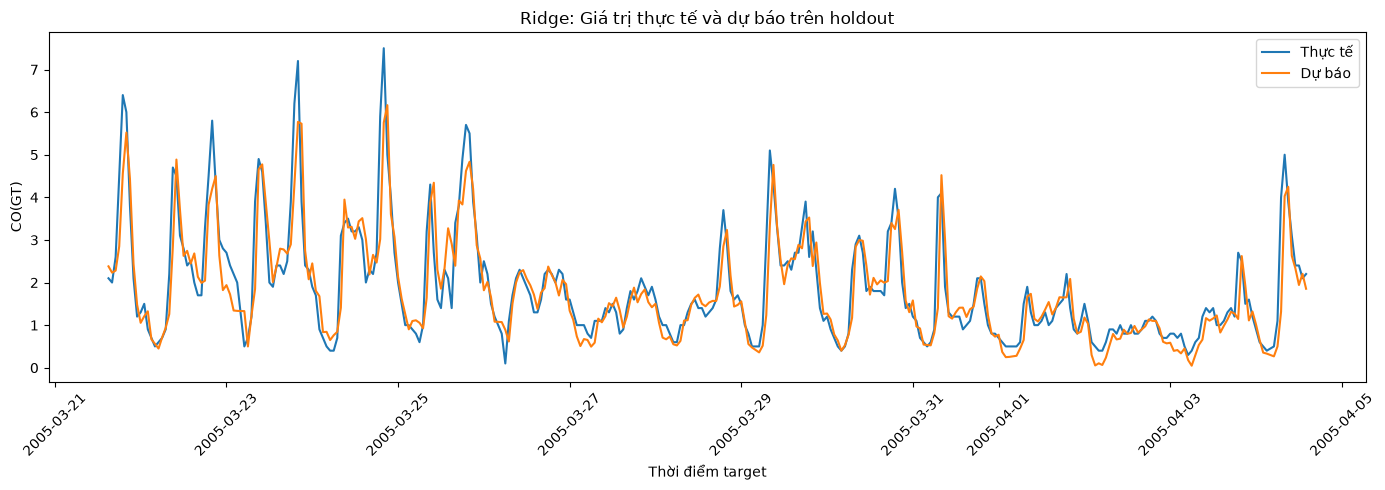

In [48]:
# Giá trị thật và dự báo trên holdout
plot_data = ridge_holdout_plot.dropna(subset=["y_true"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(plot_data.index, plot_data["y_true"], label="Thực tế")
ax.plot(plot_data.index, plot_data["y_pred"], label="Dự báo")
ax.set_title("Ridge: Giá trị thực tế và dự báo trên holdout")
ax.set_xlabel("Thời điểm target")
ax.set_ylabel("CO(GT)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

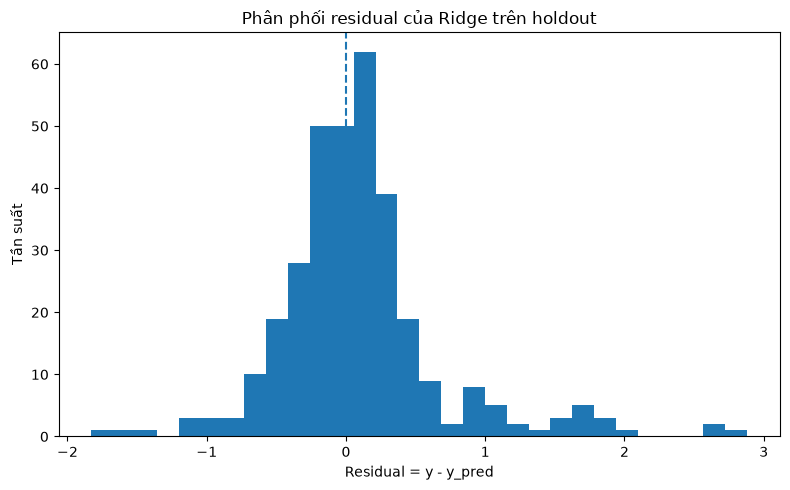

In [49]:
# Phân phối residual
residual_valid = ridge_holdout_plot["residual"].dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(residual_valid, bins=30)
ax.axvline(0, linestyle="--")
ax.set_title("Phân phối residual của Ridge trên holdout")
ax.set_xlabel("Residual = y - y_pred")
ax.set_ylabel("Tần suất")
plt.tight_layout()
plt.show()

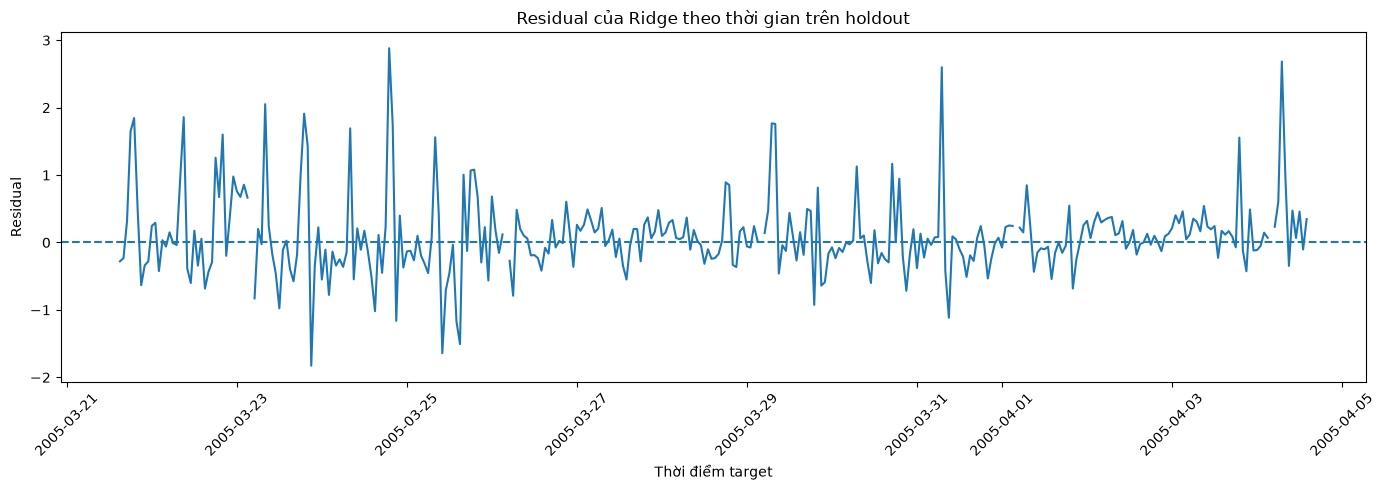

In [50]:
# Residual theo thời gian
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ridge_holdout_plot.index, ridge_holdout_plot["residual"])
ax.axhline(0, linestyle="--")
ax.set_title("Residual của Ridge theo thời gian trên holdout")
ax.set_xlabel("Thời điểm target")
ax.set_ylabel("Residual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

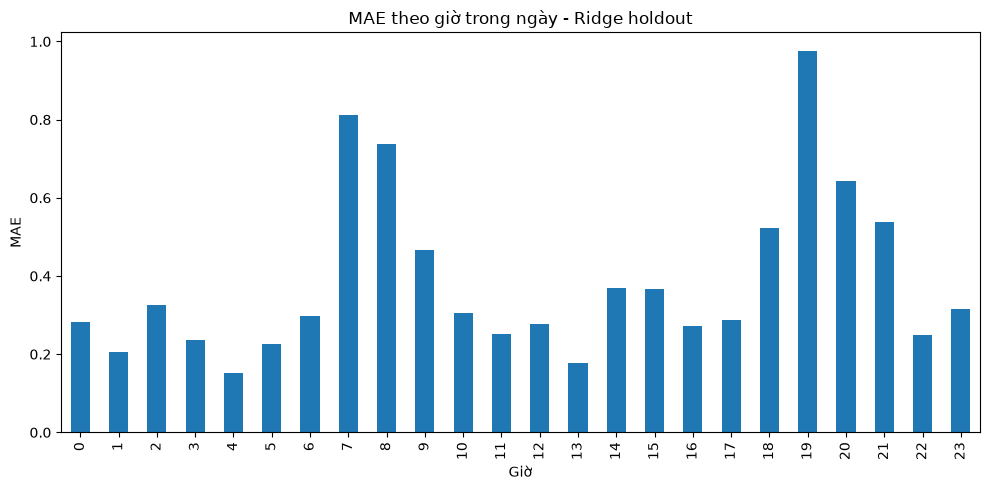

In [51]:
# MAE theo giờ trong ngày
error_data = ridge_holdout_plot.dropna(subset=["residual"]).copy()
error_data["hour"] = error_data.index.hour
error_data["abs_error"] = error_data["residual"].abs()

error_by_hour = error_data.groupby("hour")["abs_error"].mean()

plt.figure(figsize=(10, 5))
error_by_hour.plot(kind="bar")
plt.title("MAE theo giờ trong ngày - Ridge holdout")
plt.xlabel("Giờ")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

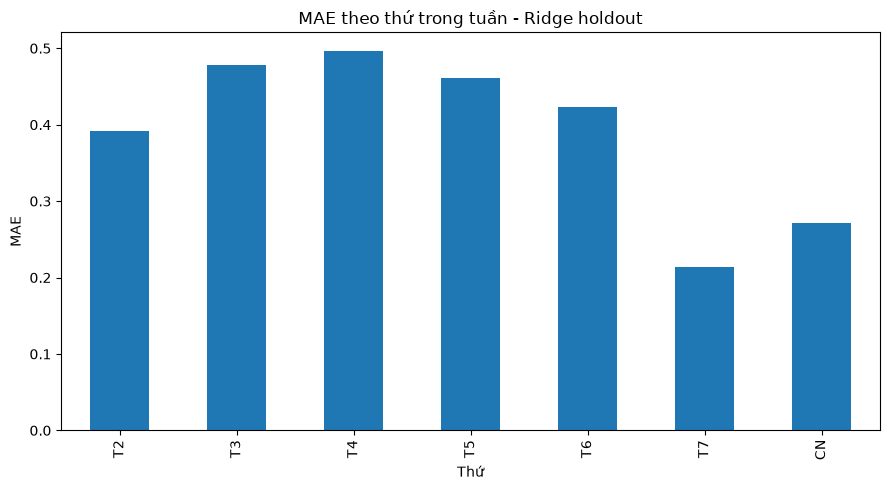

In [52]:
# MAE theo thứ trong tuần
error_data["dayofweek"] = error_data.index.dayofweek
error_by_day = error_data.groupby("dayofweek")["abs_error"].mean()
error_by_day.index = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

plt.figure(figsize=(9, 5))
error_by_day.plot(kind="bar")
plt.title("MAE theo thứ trong tuần - Ridge holdout")
plt.xlabel("Thứ")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

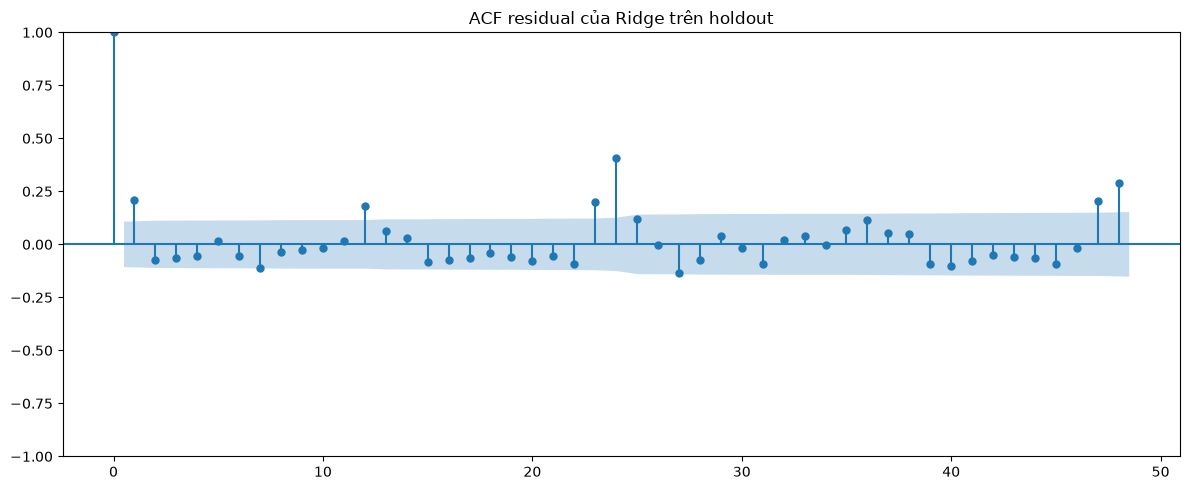

In [53]:
# ACF residual: conservative giữ nguyên vị trí thời gian khi có NaN
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(
    ridge_holdout_plot["residual"],
    lags=48,
    missing="conservative",
    ax=ax
)
ax.set_title("ACF residual của Ridge trên holdout")
plt.tight_layout()
plt.show()

## 13. Phân tích feature importance của Random Forest

Feature importance được lấy từ mô hình Random Forest đã fit trên development set. Đây là mức độ đóng góp theo tiêu chí impurity của Random Forest, không phải quan hệ nhân quả.

PT08.S2(NMHC)      0.598876
PT08.S1(CO)        0.048877
CO_roll_mean_3     0.047590
hour_cos           0.037064
hour_sin           0.024239
CO_roll_mean_24    0.021651
T                  0.019122
hour               0.018366
PT08.S5(O3)        0.017105
CO_roll_std_3      0.016689
RH                 0.015973
month              0.014995
PT08.S3(NOx)       0.014087
CO_roll_std_24     0.012945
CO_lag_1           0.011943
dtype: float64

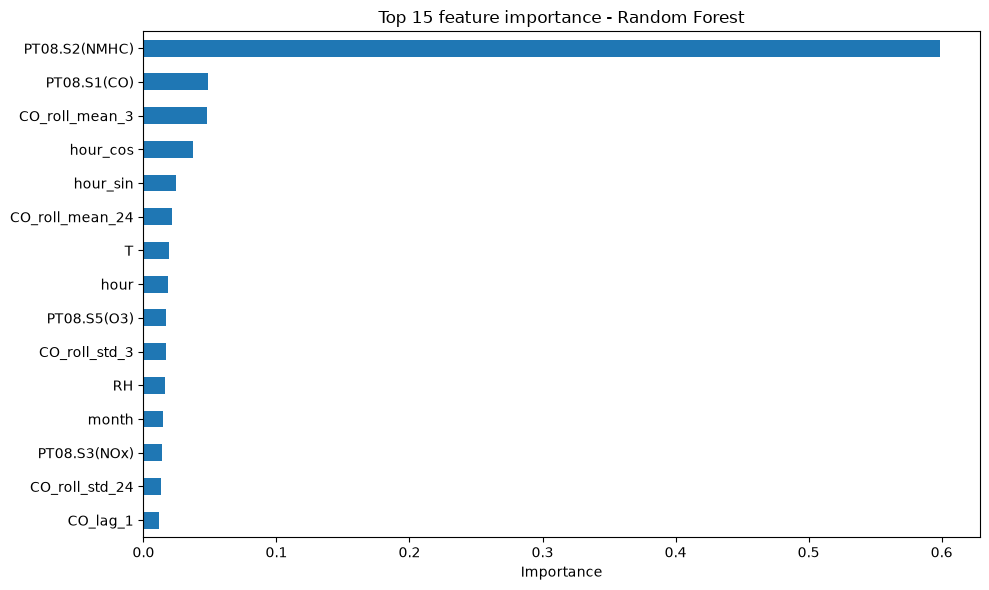

In [54]:
rf_estimator = final_rf.named_steps["model"]

feature_importance = (
    pd.Series(rf_estimator.feature_importances_, index=feature_cols)
    .sort_values(ascending=False)
)

display(feature_importance.head(15))

plt.figure(figsize=(10, 6))
feature_importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 feature importance - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 14. Kết luận

### 1. Tổng quan dữ liệu và tiền xử lý

Bài thực hành sử dụng bộ dữ liệu Air Quality gồm 9.357 mẫu quan sát theo từng giờ, với các thông tin về nồng độ khí và điều kiện môi trường. Dữ liệu có chứa nhiều giá trị thiếu được biểu diễn bằng -200, vì vậy cần chuyển các giá trị này thành NaN trước khi tiến hành phân tích.

Qua quá trình khám phá dữ liệu, có thể sử dụng các biểu đồ chuỗi thời gian, biểu đồ phân phối và ma trận tương quan để tìm hiểu đặc điểm của các biến. Kiểm định ADF cho chuỗi CO thu được p-value xấp xỉ 0, cho thấy có đủ bằng chứng bác bỏ giả thuyết chuỗi không dừng ở mức ý nghĩa 5%.

### 2. Xây dựng mô hình dự báo

Bài toán được xây dựng nhằm dự đoán nồng độ CO(GT) tại thời điểm tiếp theo (sau 1 giờ). Các đặc trưng được tạo ra bao gồm:

- Đặc trưng thời gian: giờ, ngày trong tuần, tháng và các biến chu kỳ sin/cos.

- Đặc trưng trễ (Lag): giá trị CO trong các khoảng thời gian trước đó.

- Đặc trưng cửa sổ trượt (Rolling): giá trị trung bình và độ lệch chuẩn của CO.

- Các thông số cảm biến và điều kiện môi trường.

Hai mô hình học máy được sử dụng là Ridge Regression và Random Forest Regressor. Ngoài ra, các phương pháp dự báo cơ sở gồm Persistence, Seasonal Naive 24h và Hourly Mean được sử dụng để làm cơ sở so sánh.

### 3. So sánh và đánh giá kết quả

Kết quả đánh giá bằng TimeSeriesSplit với 5 fold cho thấy Random Forest đạt MAE trung bình khoảng 0,494, thấp hơn Ridge Regression (0,553) và Persistence (0,535). Random Forest cũng đạt RMSE trung bình khoảng 0,716 và R² khoảng 0,727.

Trên tập holdout, Random Forest tiếp tục cho kết quả tốt nhất:

- MAE: 0,334

- RMSE: 0,484

- R²: 0,862

- MASE: 0,605

Trong khi đó, Ridge Regression đạt MAE 0,391 và R² 0,787. Các kết quả này cho thấy Random Forest có khả năng dự báo tốt hơn các mô hình còn lại trên tập dữ liệu được sử dụng. Giá trị MASE nhỏ hơn 1 cũng cho thấy sai số của Random Forest thấp hơn phương pháp dự báo ngây thơ dựa trên sai phân bậc một của tập huấn luyện.

### 4. Phân tích và nhận xét

Qua phân tích Feature Importance, đặc trưng PT08.S2(NMHC) có mức độ quan trọng lớn nhất trong mô hình Random Forest, chiếm khoảng 59,89% tổng mức độ quan trọng. Điều này cho thấy mô hình phụ thuộc đáng kể vào thông tin từ cảm biến này khi dự báo nồng độ CO.

Việc phân tích phần dư của Ridge Regression giúp quan sát sự khác biệt giữa giá trị thực tế và giá trị dự báo, đồng thời đánh giá sự phân bố sai số và khả năng xuất hiện tương quan theo thời gian.

### 5. Hạn chế và hướng phát triển

Mặc dù Random Forest cho kết quả tốt trong thử nghiệm, bài toán vẫn còn một số hạn chế:

Dữ liệu có nhiều giá trị thiếu, khiến số lượng mẫu có target hợp lệ dùng để đánh giá nhỏ hơn tổng số mẫu ban đầu.

Dữ liệu chỉ bao phủ một khoảng thời gian nhất định, nên chưa thể khẳng định mô hình hoạt động tốt với mọi điều kiện môi trường.

Feature Importance phản ánh mức độ đóng góp của đặc trưng trong mô hình, không đồng nghĩa với quan hệ nhân quả.

Có thể thử nghiệm thêm các mô hình khác, tối ưu siêu tham số và đánh giá trên nhiều giai đoạn dữ liệu khác nhau.

**Kết luận chung**: Qua bài thực hành, đã thực hiện được các bước từ khám phá, tiền xử lý dữ liệu, xây dựng đặc trưng thời gian đến huấn luyện và đánh giá mô hình dự báo chuỗi thời gian. Trong các phương pháp được thử nghiệm, Random Forest cho kết quả tốt nhất trên cả quá trình kiểm định chéo và tập holdout, phù hợp để lựa chọn làm mô hình dự báo CO trong phạm vi bộ dữ liệu này.